# Projet ML : prédire le résultat d'un match de football
**Données** : Transfermarkt (`games.csv`, ~89 000 matchs) · **Démarche** : Ch.2 (processus ML) → Ch.3 exploration → Ch.4 préparation → Ch.5 modélisation → Ch.6 évaluation.

**Problème** : classification supervisée à 3 classes : **victoire extérieur / match nul / victoire domicile**, prédite **avant** le match. Le fichier ne contient que les scores ; on construit donc nous-mêmes des variables de force et de forme à partir de l'historique de chaque club.

> Placer ce notebook dans le même dossier que `games.csv`.

## Carte du projet : la « chaîne du processus ML » du cours
| Étape du cours | Où dans ce notebook |
|---|---|
| 1. Récupération des données | §2 (lecture `games.csv`) · §8.1 (autres tables) |
| 2. Préparation : **Exploration** (Ch.3) | §3 + **§3 bis : les 11 graphiques du cours** |
| 2. Préparation : **Nettoyage** (Ch.4) | §4 + **§4.1 contrôles de qualité** · **§4.2 sélection / encodage** |
| 2. Préparation : **Normalisation** (Ch.4) | §5 + **§5 bis : avant / après normalisation** |
| 3. Modélisation (Ch.5) | §6 · §8.2 |
| 4. Évaluation & réglage (Ch.5-6) | §7 · **§8 bis : GridSearch, validation temporelle, courbe de validation** |
| 5. Déploiement (Ch.7) | §9 interface · **§10 : API FastAPI, tests, Docker, supervision (8 étapes)** |
| ↺ Réitérer jusqu'à performances satisfaisantes | §8 puis §8 bis : on ajoute des variables, on règle, on compare à la référence |

## 1. Importation des bibliothèques

In [1]:
import pandas as pd            # manipulation des tableaux
import numpy as np             # calcul numérique
import matplotlib.pyplot as plt  # graphiques
from sklearn.model_selection import train_test_split   # séparation train/test
from sklearn.preprocessing import StandardScaler       # normalisation
from sklearn.linear_model import LogisticRegression    # modèle 1
from sklearn.tree import DecisionTreeClassifier        # modèle 2
from sklearn.ensemble import RandomForestClassifier    # modèle 3
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay  # métriques

In [2]:
# --- imports supplémentaires (visualisation, réglage, déploiement) ---
%pip install -q seaborn
import os, sys, json, time, hashlib, subprocess, warnings
from pathlib import Path
import seaborn as sns                                   # graphiques statistiques (boîte, violon, heatmap)
from pandas.plotting import scatter_matrix              # matrice de dispersion
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings('ignore')

# --- style commun : palette validée (bleu / vert / orange = domicile / nul / extérieur) ---
COUL = {'Victoire domicile': '#2a78d6', 'Nul': '#1baf7a', 'Victoire extérieur': '#eb6834'}
SEQ = LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])   # dégradé séquentiel (une teinte)
DIV = LinearSegmentedColormap.from_list('div', ['#eb6834', '#f0efec', '#2a78d6'])                          # divergent (neutre au milieu)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'text.color': '#0b0b0b',
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'legend.frameon': False, 'figure.dpi': 100})

Note: you may need to restart the kernel to use updated packages.


## 2. Récupération des données (Ch.2)

In [3]:
from pathlib import Path
# Recherche relative du dataset, puis emplacements Windows usuels
candidats = [Path.cwd(), Path.cwd().parent / 'archive', Path.home() / 'Downloads' / 'archive']
DATA_DIR = next((p for p in candidats if (p / 'games.csv').exists()), Path.home() / 'Downloads' / 'archive')
print('Dataset recherché dans :', DATA_DIR)
df = pd.read_csv(DATA_DIR / 'games.csv')
df.head()

Dataset recherché dans : C:\Users\ayoub\Downloads\archive


,game_id,competition_id,season,round,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,...,stadium,attendance,referee,url,home_club_formation,away_club_formation,home_club_name,away_club_name,aggregate,competition_type
0,1026846,FIWC,2009,Round of 16,2010-06-26,3449,3589,2,1,NaN,...,Nelson Mandela Bay Stadium,30597.0,Wolfgang Stark,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Uruguay,South Korea,2:1,national_team_competition
1,1026847,FIWC,2009,Round of 16,2010-06-27,3437,6303,3,1,NaN,...,FNB-Stadium,84377.0,Roberto Rosetti,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Argentina,Mexico,3:1,national_team_competition
2,1027001,FIWC,2009,Round of 16,2010-06-26,3505,3441,1,2,NaN,...,Royal Bafokeng Stadium,34976.0,Viktor Kassai,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,United States,Ghana,1:2,national_team_competition
3,1027002,FIWC,2009,Round of 16,2010-06-27,3262,3299,4,1,NaN,...,Free State Stadium,40510.0,Jorge Larrionda,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Germany,England,4:1,national_team_competition
4,1027048,FIWC,2009,Round of 16,2010-06-28,3379,3503,2,1,NaN,...,Moses Mabhida Stadion,61962.0,Undiano Mallenco,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Netherlands,Slovakia,2:1,national_team_competition


## 3. Exploration (Ch.3)

In [4]:
print(df.shape)                                       # lignes x colonnes
print(df.duplicated('game_id').sum(), 'doublons')         # doublons sur l'identifiant du match
manq = df.isnull().sum()                                  # valeurs manquantes par colonne
manq[manq > 0]

(88958, 23)
0 doublons


home_club_position        25377
away_club_position        25377
home_club_manager_name      844
away_club_manager_name      844
stadium                     242
attendance                10803
referee                     678
home_club_formation        8200
away_club_formation        8073
home_club_name               86
away_club_name               36
competition_type           1214
dtype: int64

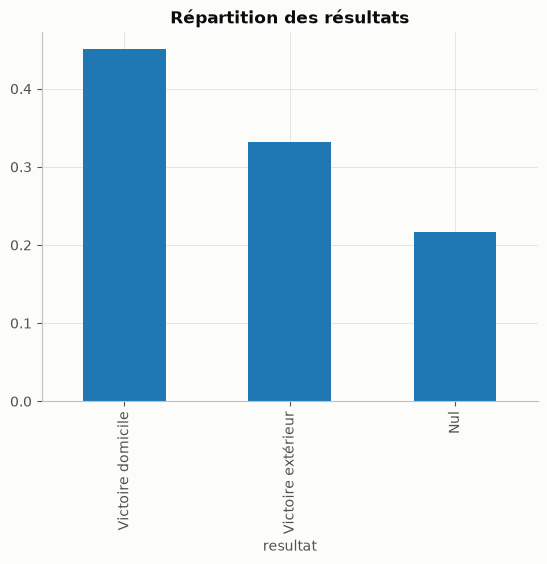

In [5]:
df['resultat'] = np.select([df['home_club_goals'] > df['away_club_goals'], df['home_club_goals'] < df['away_club_goals']],
                            ['Victoire domicile', 'Victoire extérieur'], default='Nul')   # résultat du match
df['resultat'].value_counts(normalize=True).plot(kind='bar', title='Répartition des résultats')  # classes déséquilibrées
plt.show()

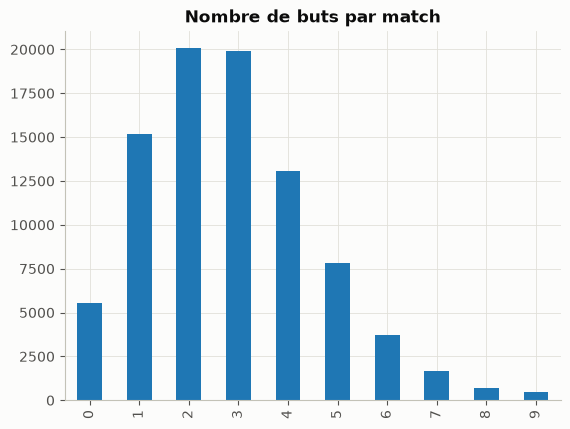

In [6]:
(df['home_club_goals'] + df['away_club_goals']).value_counts().sort_index().head(10).plot(kind='bar', title='Nombre de buts par match')  # distribution des buts
plt.show()

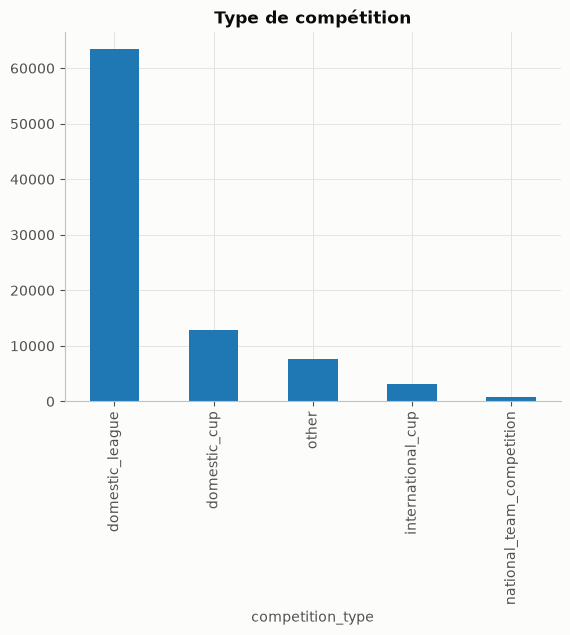

In [7]:
df['competition_type'].value_counts().plot(kind='bar', title='Type de compétition')   # types de matchs
plt.show()

In [8]:
df.groupby('competition_type')['resultat'].value_counts(normalize=True).unstack().round(2)   # avantage du terrain par type de compétition

resultat,Nul,Victoire domicile,Victoire extérieur
competition_type,,,
domestic_cup,0.06,0.46,0.48
domestic_league,0.25,0.44,0.31
international_cup,0.21,0.48,0.31
national_team_competition,0.19,0.45,0.36
other,0.22,0.48,0.31


**Constats** : le domicile gagne environ 45 % des matchs (avantage du terrain), le nul environ 22 %. Une prédiction naïve « toujours victoire domicile » donne déjà ~45 % : c'est notre **référence** à battre. Le fichier n'a pas de variable de « force » des clubs : il faut la construire.

## 3 bis. Les 11 graphiques du cours (Ch.3)
Un graphique par type vu en cours, tous sur les données de matchs : **courbes, bulles, nuage de points, barres verticales, barres horizontales, histogramme, boîte, violon, circulaire, heatmap, matrice de dispersion**.

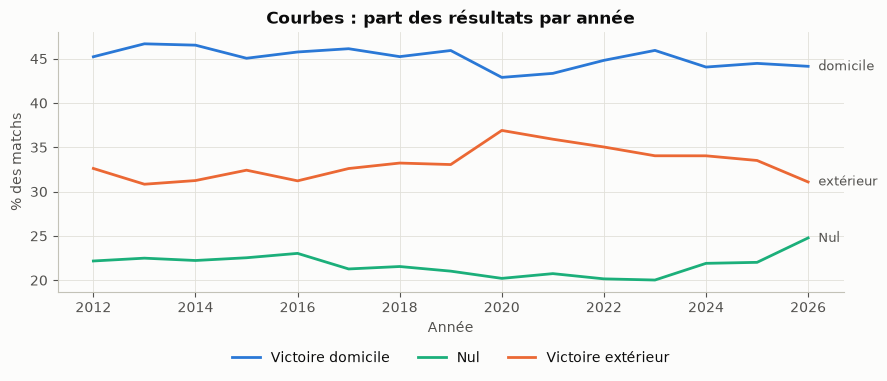

In [9]:
# 1) COURBES : évolution de la part des résultats au fil des années
d = df.assign(annee=pd.to_datetime(df['date'], errors='coerce').dt.year)
eff = pd.crosstab(d['annee'], d['resultat'])
t = pd.crosstab(d['annee'], d['resultat'], normalize='index').mul(100)[eff.sum(axis=1) >= 200]   # années avec assez de matchs
fig, ax = plt.subplots(figsize=(9, 4))
for r, c in COUL.items():
    ax.plot(t.index, t[r], color=c, lw=2, label=r)
    ax.text(t.index[-1] + 0.2, t[r].iloc[-1], r.replace('Victoire ', ''), color='#52514e', va='center', fontsize=9)   # étiquette directe
ax.set(title='Courbes : part des résultats par année', xlabel='Année', ylabel='% des matchs')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3); plt.tight_layout(); plt.show()

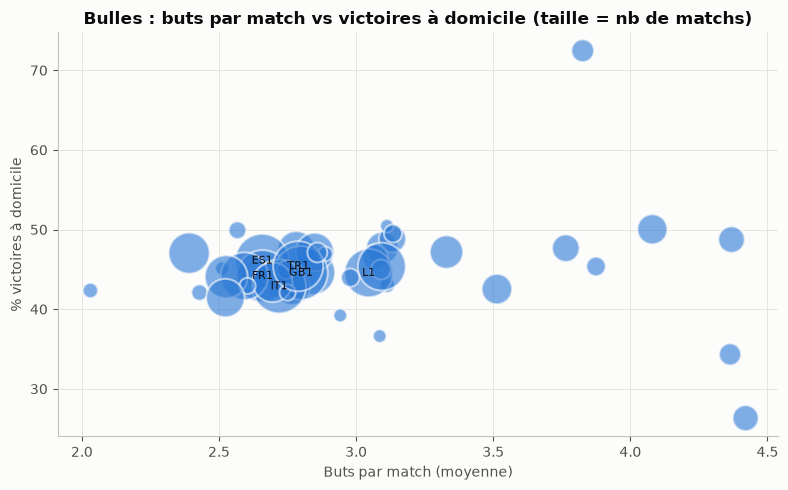

In [10]:
# 2) GRAPHIQUE À BULLES : une bulle = une compétition (taille = nombre de matchs)
g = df.assign(buts=df['home_club_goals'] + df['away_club_goals'], dom=(df['resultat'] == 'Victoire domicile') * 100) \
      .groupby('competition_id').agg(n=('game_id', 'count'), buts=('buts', 'mean'), dom=('dom', 'mean'))
g = g[g['n'] >= 300]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(g['buts'], g['dom'], s=g['n'] / g['n'].max() * 1500, color='#2a78d6', alpha=0.6, edgecolor='#fcfcfb', linewidth=1.5)
for cid, r in g.nlargest(6, 'n').iterrows():
    ax.annotate(cid, (r['buts'], r['dom']), ha='center', va='center', fontsize=8, color='#0b0b0b')
ax.set(title='Bulles : buts par match vs victoires à domicile (taille = nb de matchs)', xlabel='Buts par match (moyenne)', ylabel='% victoires à domicile')
plt.tight_layout(); plt.show()

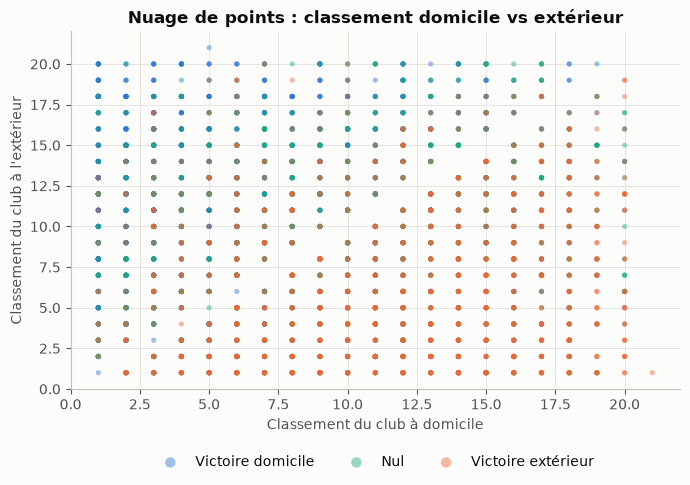

In [11]:
# 3) NUAGE DE POINTS : classement du club à domicile vs à l'extérieur, coloré par résultat
cols = ['home_club_position', 'away_club_position']
p = df[cols + ['resultat']].dropna()
p = p.sample(min(4000, len(p)), random_state=42)
fig, ax = plt.subplots(figsize=(7, 5))
for r, c in COUL.items():
    q = p[p['resultat'] == r]
    ax.scatter(q[cols[0]], q[cols[1]], s=14, alpha=0.45, color=c, label=r, edgecolor='none')
ax.set(title='Nuage de points : classement domicile vs extérieur', xlabel='Classement du club à domicile', ylabel="Classement du club à l'extérieur")
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, markerscale=2); plt.tight_layout(); plt.show()

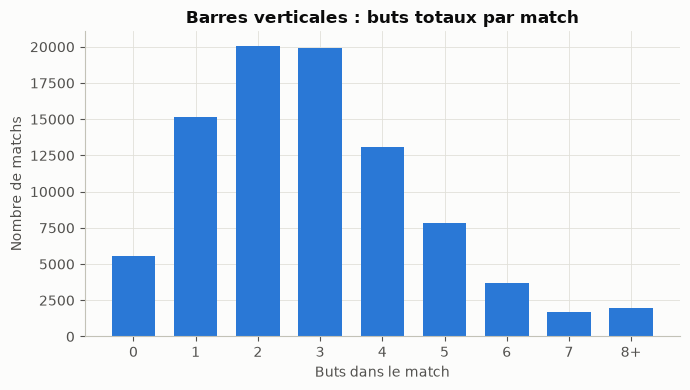

In [12]:
# 4) BARRES VERTICALES : nombre de matchs selon le total de buts
buts = (df['home_club_goals'] + df['away_club_goals']).clip(upper=8).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(i) if i < 8 else '8+' for i in buts.index], buts.values, color='#2a78d6', width=0.7)
ax.set(title='Barres verticales : buts totaux par match', xlabel='Buts dans le match', ylabel='Nombre de matchs')
plt.tight_layout(); plt.show()

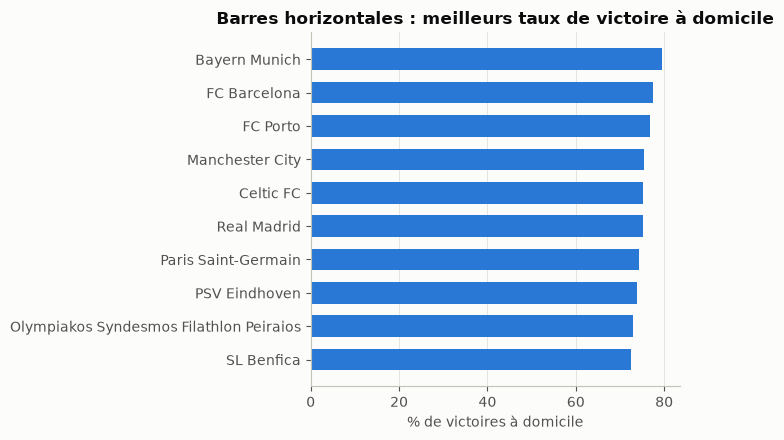

In [13]:
# 5) BARRES HORIZONTALES : 10 clubs avec le meilleur taux de victoires à domicile (>= 150 matchs à domicile)
c = df.assign(dom=(df['resultat'] == 'Victoire domicile') * 100).groupby('home_club_name').agg(n=('game_id', 'count'), dom=('dom', 'mean'))
c = c[c['n'] >= 150].nlargest(10, 'dom').sort_values('dom')
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(c.index, c['dom'], color='#2a78d6', height=0.65)
ax.set(title='Barres horizontales : meilleurs taux de victoire à domicile', xlabel='% de victoires à domicile')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

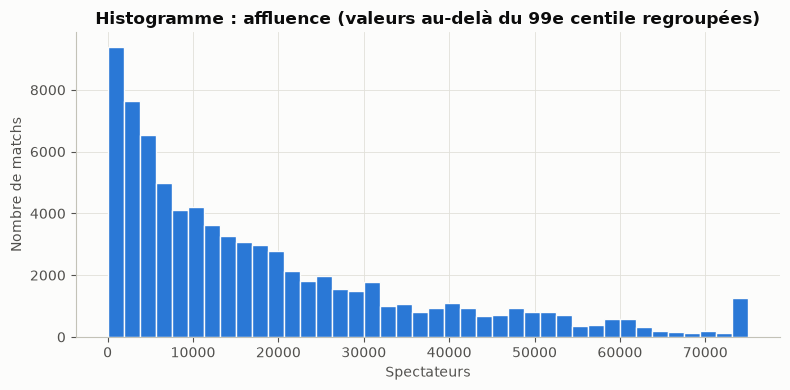

In [14]:
# 6) HISTOGRAMME : distribution de l'affluence (spectateurs)
att = pd.to_numeric(df['attendance'], errors='coerce').dropna()
att = att[att > 0]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(att.clip(upper=att.quantile(0.99)), bins=40, color='#2a78d6', edgecolor='#fcfcfb', linewidth=1)
ax.set(title="Histogramme : affluence (valeurs au-delà du 99e centile regroupées)", xlabel='Spectateurs', ylabel='Nombre de matchs')
plt.tight_layout(); plt.show()

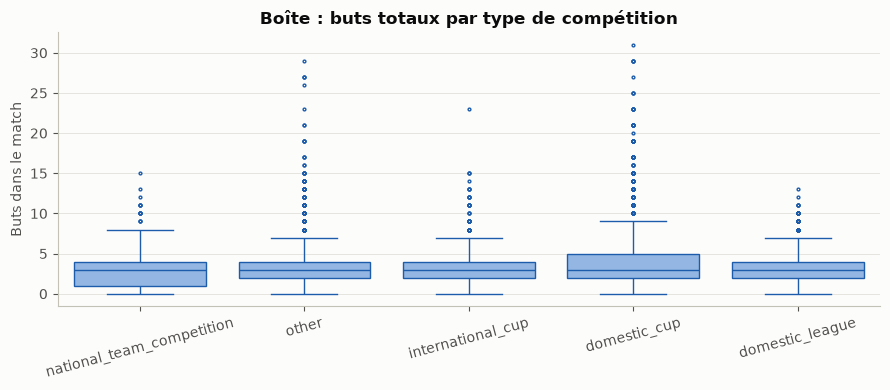

In [15]:
# 7) DIAGRAMME EN BOÎTE : buts totaux selon le type de compétition (médiane, quartiles, valeurs extrêmes)
b = df.assign(buts=df['home_club_goals'] + df['away_club_goals'], diff=df['home_club_goals'] - df['away_club_goals'],
              type=df['competition_type'].fillna('other'))
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=b, x='type', y='buts', color='#86b6ef', linecolor='#1c5cab', fliersize=2, ax=ax)
ax.set(title='Boîte : buts totaux par type de compétition', xlabel='', ylabel='Buts dans le match')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

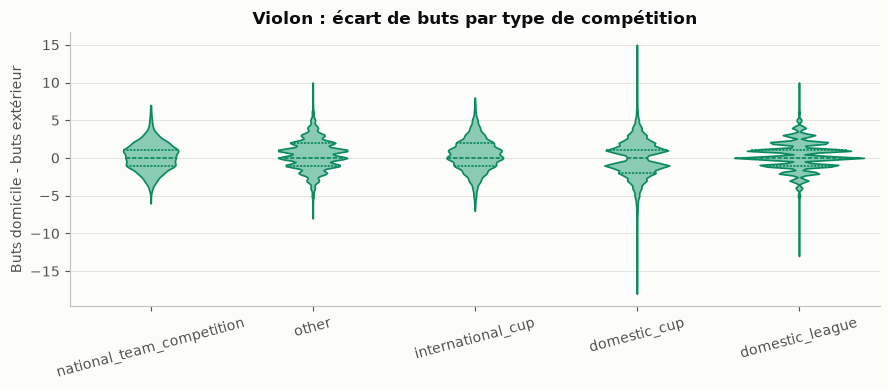

In [16]:
# 8) DIAGRAMME EN VIOLON : écart de buts (domicile - extérieur) par type de compétition (forme complète de la distribution)
fig, ax = plt.subplots(figsize=(9, 4))
sns.violinplot(data=b, x='type', y='diff', color='#7fd6b6', linecolor='#0b8a5f', inner='quartile', cut=0, ax=ax)
ax.set(title='Violon : écart de buts par type de compétition', xlabel='', ylabel='Buts domicile - buts extérieur')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

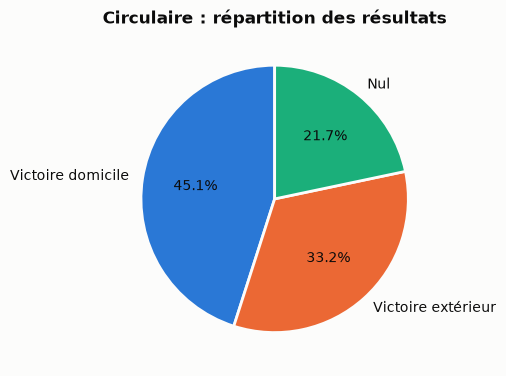

In [17]:
# 9) DIAGRAMME CIRCULAIRE : répartition des 3 résultats
s = df['resultat'].value_counts()
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(s.values, labels=s.index, colors=[COUL[i] for i in s.index], autopct='%1.1f%%', startangle=90, textprops={'color': '#0b0b0b'},
       wedgeprops={'edgecolor': '#fcfcfb', 'linewidth': 2})
ax.set_title('Circulaire : répartition des résultats'); plt.tight_layout(); plt.show()

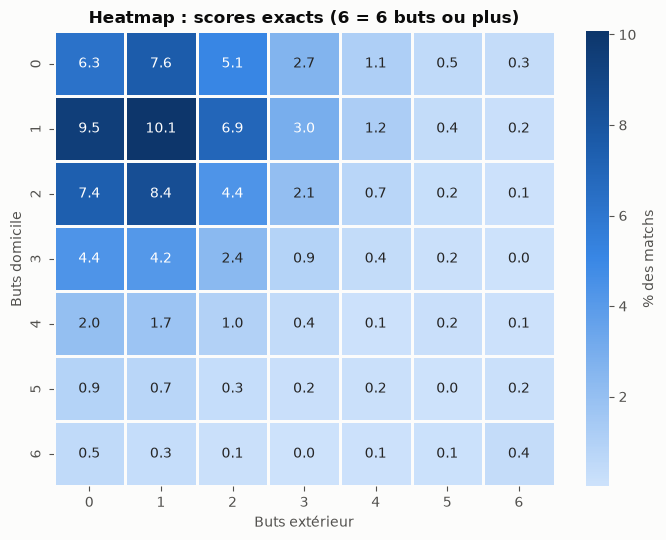

In [18]:
# 10) HEATMAP : fréquence (%) de chaque score exact (buts domicile en lignes, buts extérieur en colonnes)
ct = pd.crosstab(df['home_club_goals'].clip(upper=6), df['away_club_goals'].clip(upper=6), normalize=True).mul(100)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(ct, annot=True, fmt='.1f', cmap=SEQ, linewidths=2, linecolor='#fcfcfb', cbar_kws={'label': '% des matchs'}, ax=ax)
ax.set(title='Heatmap : scores exacts (6 = 6 buts ou plus)', xlabel='Buts extérieur', ylabel='Buts domicile'); ax.grid(False)
plt.tight_layout(); plt.show()

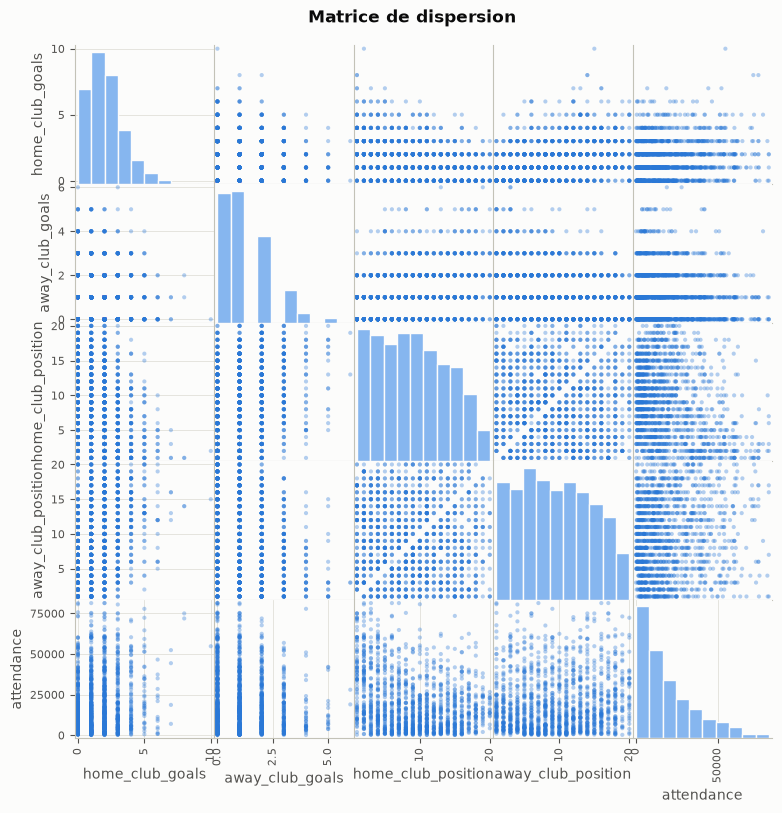

In [19]:
# 11) MATRICE DE DISPERSION : relations deux à deux entre les variables numériques brutes
num_brutes = [c for c in ['home_club_goals', 'away_club_goals', 'home_club_position', 'away_club_position', 'attendance'] if df[c].notna().mean() > 0.5]
m = df[num_brutes].apply(pd.to_numeric, errors='coerce').dropna()
m = m.sample(min(1500, len(m)), random_state=42)
pd.plotting.scatter_matrix(m, figsize=(9, 9), diagonal='hist', alpha=0.35, color='#2a78d6', hist_kwds={'color': '#86b6ef', 'edgecolor': '#fcfcfb'})
plt.suptitle('Matrice de dispersion', y=0.92, fontweight='bold'); plt.show()

## 4. Préparation (Ch.4)
**Choix documentés :**
- doublons supprimés (`game_id`), matchs triés par date ;
- colonnes inutiles supprimées (URL, arbitre, stade, entraîneurs, affluence : inconnus ou peu utiles) ;
- `competition_type` manquant → « other » ;
- **aucune fuite de données** : on n'utilise que des informations connues *avant* le coup d'envoi (jamais le score du match lui-même) ;
- variables construites en parcourant les matchs **dans l'ordre chronologique** :
  - **Elo** (note de force, 1500 au départ, mise à jour après chaque match, +100 d'avantage au domicile) ;
  - **forme** : points moyens par match sur les 5 derniers matchs ;
  - **buts marqués / encaissés** en moyenne sur les 5 derniers matchs ;
- on ne garde que les matchs où les deux équipes ont **au moins 5 matchs** d'historique (sinon la forme n'est pas fiable) ;
- `get_dummies(drop_first=True)` pour le type de compétition, `StandardScaler` pour les numériques.

In [20]:
df = df.drop_duplicates('game_id')                                   # suppression des doublons
df = df.sort_values(['date', 'game_id']).reset_index(drop=True)          # ordre chronologique (indispensable)
df['competition_type'] = df['competition_type'].fillna('other')           # type manquant -> other

### 4.1 Nettoyage complet (Ch.4) : toutes les vérifications, même si les données sont déjà propres
Chaque contrôle du cours est exécuté ; quand il ne trouve rien, c'est **documenté** (« 0 problème ») au lieu d'être ignoré.

Doublons sur game_id (après suppression) : 0
Lignes totalement identiques             : 0


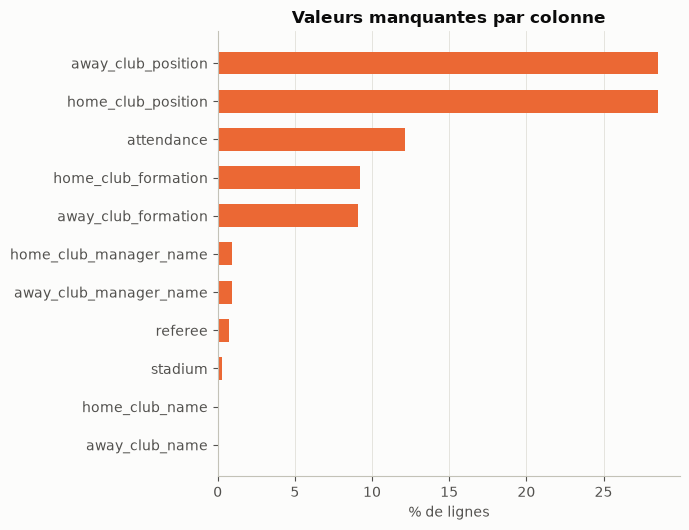

,manquantes,%
home_club_position,25377,28.53
away_club_position,25377,28.53
attendance,10803,12.14
home_club_formation,8200,9.22
away_club_formation,8073,9.08
home_club_manager_name,844,0.95
away_club_manager_name,844,0.95
referee,678,0.76
stadium,242,0.27
home_club_name,86,0.10


In [21]:
# --- (a) Valeurs manquantes : comptage et visualisation ---
manq = df.isna().sum().to_frame('manquantes'); manq['%'] = (manq['manquantes'] / len(df) * 100).round(2)
print('Doublons sur game_id (après suppression) :', df.duplicated('game_id').sum())
print('Lignes totalement identiques             :', df.duplicated().sum())
mm = manq[manq['manquantes'] > 0].sort_values('%')
fig, ax = plt.subplots(figsize=(7, max(2, 0.4 * len(mm) + 1)))
ax.barh(mm.index, mm['%'], color='#eb6834', height=0.6)
ax.set(title='Valeurs manquantes par colonne', xlabel='% de lignes'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
manq[manq['manquantes'] > 0].sort_values('%', ascending=False)

In [22]:
# --- (b) Types et conversions : to_datetime / to_numeric (errors='coerce' transforme l'illisible en NaN) ---
avant = df[['home_club_goals', 'away_club_goals', 'attendance']].isna().sum().sum()
dates = pd.to_datetime(df['date'], errors='coerce')
nums = df[['home_club_goals', 'away_club_goals', 'attendance']].apply(pd.to_numeric, errors='coerce')
print('Dates illisibles     :', dates.isna().sum())
print('Valeurs converties en NaN par to_numeric :', nums.isna().sum().sum() - avant)
for c in ['home_club_goals', 'away_club_goals']: df[c] = nums[c]           # buts : numériques (aucune valeur modifiée si déjà propres)
print('Période :', dates.min().date(), '->', dates.max().date())
print('Types :', df[['home_club_goals', 'away_club_goals', 'home_club_id', 'away_club_id']].dtypes.astype(str).to_dict())

# --- (c) Cohérence logique ---
print('Buts négatifs        :', int(((df['home_club_goals'] < 0) | (df['away_club_goals'] < 0)).sum()))
print('Club contre lui-même :', int((df['home_club_id'] == df['away_club_id']).sum()))
print('Dates dans le futur  :', int((dates > pd.Timestamp.today()).sum()))

Dates illisibles     : 0
Valeurs converties en NaN par to_numeric : 0
Période : 2006-06-09 -> 2026-07-06
Types : {'home_club_goals': 'int64', 'away_club_goals': 'int64', 'home_club_id': 'int64', 'away_club_id': 'int64'}
Buts négatifs        : 0
Club contre lui-même : 0
Dates dans le futur  : 0


In [23]:
# --- (d) Valeurs aberrantes : règle IQR (Q1 - 1,5 IQR ; Q3 + 1,5 IQR) ---
def iqr_bornes(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i
lignes = []
for c in ['home_club_goals', 'away_club_goals']:
    lo, hi = iqr_bornes(df[c]); lignes.append([c, lo, hi, int(((df[c] < lo) | (df[c] > hi)).sum())])
att = pd.to_numeric(df['attendance'], errors='coerce').dropna()
lo, hi = iqr_bornes(att); lignes.append(['attendance', lo, hi, int(((att < lo) | (att > hi)).sum())])
print(pd.DataFrame(lignes, columns=['colonne', 'borne basse', 'borne haute', 'nb hors bornes']).round(1).to_string(index=False))
print('Décision : on CONSERVE ces valeurs (gros scores et grandes affluences réels, pas des erreurs de saisie) ; suppression seulement si erreur prouvée.')

        colonne  borne basse  borne haute  nb hors bornes
home_club_goals         -0.5          3.5            8433
away_club_goals         -3.0          5.0            1086
     attendance     -28483.2      59254.8            3305
Décision : on CONSERVE ces valeurs (gros scores et grandes affluences réels, pas des erreurs de saisie) ; suppression seulement si erreur prouvée.


In [24]:
# --- (e) Traitement : colonnes inutiles (sur une COPIE, car l'interface du §9 réutilise certaines colonnes) + imputation documentée ---
inutiles = ['url', 'referee', 'stadium', 'home_club_manager_name', 'away_club_manager_name', 'attendance', 'aggregate', 'round', 'home_club_formation', 'away_club_formation']
inutiles = [c for c in inutiles if c in df.columns]
df_nettoye = df.drop(columns=inutiles).copy()
print('Colonnes retirées de la copie de travail :', inutiles)
# imputation : mode pour une catégorie, médiane pour un numérique (robuste aux extrêmes), 0 si l'absence a un sens
for c in df_nettoye.columns[df_nettoye.isna().any()]:
    if df_nettoye[c].dtype == object: df_nettoye[c] = df_nettoye[c].fillna(df_nettoye[c].mode().iloc[0])
    elif c.endswith('position'): df_nettoye[c] = df_nettoye[c].fillna(df_nettoye[c].median())
print('Manquantes restantes dans les colonnes utiles :', int(df_nettoye[['home_club_goals', 'away_club_goals', 'competition_type', 'resultat']].isna().sum().sum()))

Colonnes retirées de la copie de travail : ['url', 'referee', 'stadium', 'home_club_manager_name', 'away_club_manager_name', 'attendance', 'aggregate', 'round', 'home_club_formation', 'away_club_formation']
Manquantes restantes dans les colonnes utiles : 0


In [25]:
elo, hist = {}, {}                  # note Elo et historique (points, buts pour, buts contre) de chaque club
lignes = []                           # une ligne de variables par match

def forme(h):                          # résumé des 5 derniers matchs d'un club
    d = h[-5:]
    return [len(h), np.mean([x[0] for x in d]), np.mean([x[1] for x in d]), np.mean([x[2] for x in d])] if d else [0, np.nan, np.nan, np.nan]

for r in df.itertuples():             # on parcourt les matchs du plus ancien au plus récent
    h, a = r.home_club_id, r.away_club_id
    eh, ea = elo.get(h, 1500), elo.get(a, 1500)                 # Elo AVANT le match
    fh, fa = forme(hist.get(h, [])), forme(hist.get(a, []))     # forme AVANT le match
    lignes.append([eh, ea] + fh + fa)
    gh, ga = r.home_club_goals, r.away_club_goals               # on met à jour SEULEMENT après avoir enregistré les variables
    s = 1 if gh > ga else (0.5 if gh == ga else 0)             # score réel du domicile (1 / 0.5 / 0)
    attendu = 1 / (1 + 10 ** ((ea - eh - 100) / 400))           # score attendu (avec avantage du terrain)
    elo[h] = eh + 20 * (s - attendu); elo[a] = ea - 20 * (s - attendu)   # mise à jour Elo (K = 20)
    hist.setdefault(h, []).append((3 if s == 1 else (1 if s == 0.5 else 0), gh, ga))
    hist.setdefault(a, []).append((3 if s == 0 else (1 if s == 0.5 else 0), ga, gh))

cols = ['elo_dom', 'elo_ext', 'nb_dom', 'pts_dom', 'bp_dom', 'bc_dom', 'nb_ext', 'pts_ext', 'bp_ext', 'bc_ext']
df[cols] = lignes                      # ajout des variables au tableau
df['elo_diff'] = df['elo_dom'] - df['elo_ext']       # écart de force
df['pts_diff'] = df['pts_dom'] - df['pts_ext']       # écart de forme

In [26]:
df = df[(df['nb_dom'] >= 5) & (df['nb_ext'] >= 5)].copy()      # on garde les matchs avec assez d'historique
print(df.shape)
df['resultat'].value_counts(normalize=True).round(3)   # répartition finale des classes

(80044, 36)


resultat
Victoire domicile     0.452
Victoire extérieur    0.321
Nul                   0.227
Name: proportion, dtype: float64

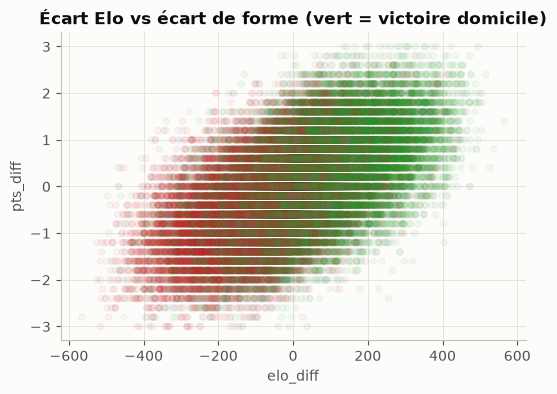

In [27]:
df.plot(kind='scatter', x='elo_diff', y='pts_diff', c=df['resultat'].map({'Victoire domicile': 'tab:green', 'Nul': 'tab:gray', 'Victoire extérieur': 'tab:red'}), alpha=0.05, figsize=(6, 4))
plt.title('Écart Elo vs écart de forme (vert = victoire domicile)'); plt.show()   # contrôle visuel des variables créées

In [28]:
num = ['elo_dom', 'elo_ext', 'elo_diff', 'pts_dom', 'pts_ext', 'pts_diff', 'bp_dom', 'bc_dom', 'bp_ext', 'bc_ext']   # variables numériques
X = pd.get_dummies(df[num + ['competition_type']], columns=['competition_type'], drop_first=True, dtype=int)   # encodage
y = df['resultat'].map({'Victoire extérieur': 0, 'Nul': 1, 'Victoire domicile': 2})     # cible numérique
print(X.shape)

(80044, 14)


### 4.2 Sélection, encodage et contrôle final (Ch.4)
Table d'apprentissage `df_ml` (variables + cible), vérification absence de NaN/infini, comparaison des **3 encodages du cours** (LabelEncoder ordonné, `get_dummies`, `OneHotEncoder`).

In [29]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
df_ml = df[num + ['competition_type', 'resultat']].copy()                       # table finale : variables + cible
print('NaN :', int(df_ml.isna().sum().sum()), '| infinis :', int(np.isinf(df_ml[num]).sum().sum()), '| forme', df_ml.shape)

# 1) LabelEncoder avec ORDRE IMPOSÉ pour la cible (extérieur < nul < domicile)
ordre = ['Victoire extérieur', 'Nul', 'Victoire domicile']
le = LabelEncoder().fit(ordre)                                               # LabelEncoder trie par ordre alphabétique
print('LabelEncoder (tri alphabétique) :', dict(zip(le.classes_, le.transform(le.classes_))), '-> ordre non voulu, donc on impose :')
print('map manuel :', {c: i for i, c in enumerate(ordre)})

# 2) variable sans ordre naturel (type de compétition) : one-hot, jamais LabelEncoder
oh = OneHotEncoder(drop='first', sparse_output=False).fit(df_ml[['competition_type']])
print('get_dummies :', X.filter(like='competition_type').shape[1], 'colonnes | OneHotEncoder :', oh.transform(df_ml[['competition_type']]).shape[1], 'colonnes (identique)')

NaN : 0 | infinis : 0 | forme (80044, 12)
LabelEncoder (tri alphabétique) : {np.str_('Nul'): np.int64(0), np.str_('Victoire domicile'): np.int64(1), np.str_('Victoire extérieur'): np.int64(2)} -> ordre non voulu, donc on impose :
map manuel : {'Victoire extérieur': 0, 'Nul': 1, 'Victoire domicile': 2}
get_dummies : 4 colonnes | OneHotEncoder : 4 colonnes (identique)


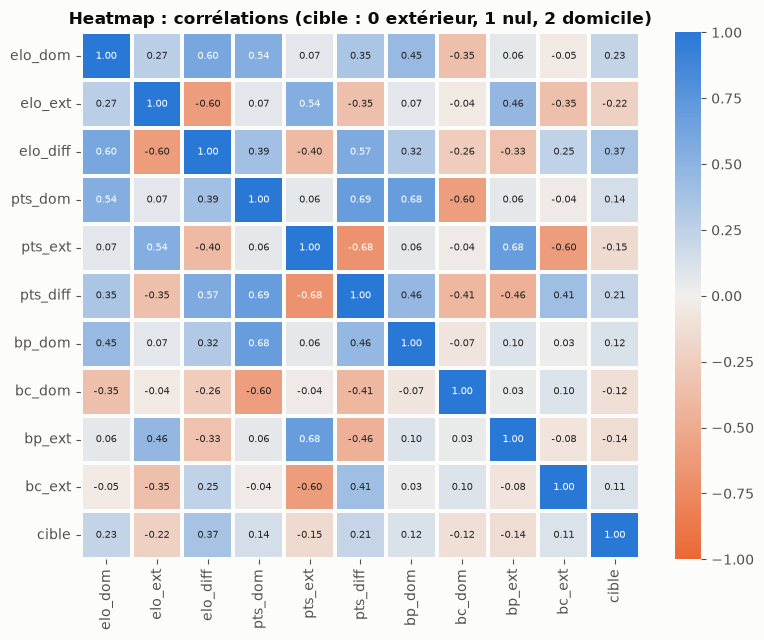

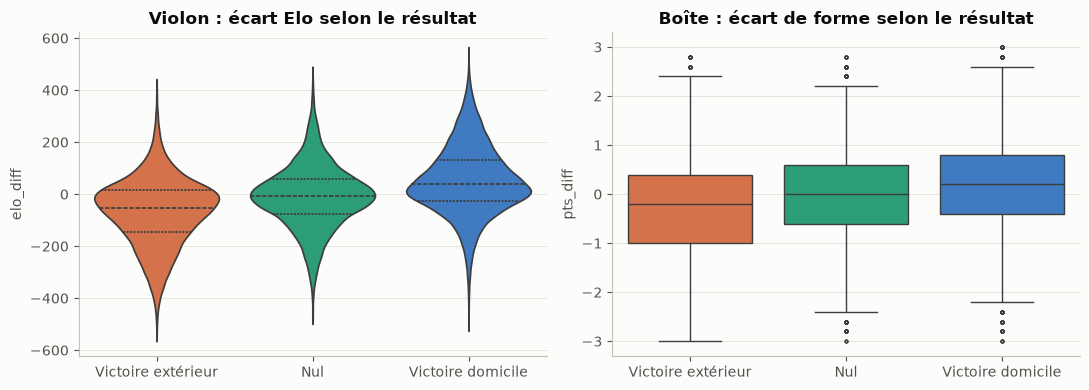

In [30]:
# Graphiques des variables construites (Elo, forme) : heatmap de corrélation, violon et boîte par résultat
corr = df[num].assign(cible=y).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap=DIV, center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=1.5, linecolor='#fcfcfb', ax=ax)
ax.set_title('Heatmap : corrélations (cible : 0 extérieur, 1 nul, 2 domicile)'); ax.grid(False); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ordre_r = ['Victoire extérieur', 'Nul', 'Victoire domicile']
sns.violinplot(data=df, x='resultat', y='elo_diff', order=ordre_r, palette=COUL, inner='quartile', cut=0, ax=axes[0])
axes[0].set(title='Violon : écart Elo selon le résultat', xlabel='', ylabel='elo_diff')
sns.boxplot(data=df, x='resultat', y='pts_diff', order=ordre_r, palette=COUL, fliersize=2, ax=axes[1])
axes[1].set(title='Boîte : écart de forme selon le résultat', xlabel='', ylabel='pts_diff')
plt.tight_layout(); plt.show()

## 5. Séparation et normalisation (Ch.5)
Séparation 80/20 stratifiée. Le `StandardScaler` est ajusté **sur le train seulement**, puis appliqué au test.

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, stratify=y, random_state=42)  # 80% / 20%
sc = StandardScaler().fit(X_train[num])               # moyenne/écart-type du train
X_train, X_test = X_train.copy(), X_test.copy()
X_train[num] = sc.transform(X_train[num]); X_test[num] = sc.transform(X_test[num])   # normalisation
reference = y_test.value_counts(normalize=True).max()   # référence : toujours prédire la classe majoritaire
print(X_train.shape, X_test.shape, '| référence :', round(reference, 3))

(64035, 14) (16009, 14) | référence : 0.452


### 5 bis. Normalisation : avant / après (Ch.4)
`StandardScaler` (moyenne 0, écart-type 1) est retenu car les modèles linéaires et distances y sont sensibles et que les variables ont des unités différentes (Elo ~1500, forme ~1,5). `MinMaxScaler` est montré pour comparaison. Les paramètres sont appris **sur le train uniquement**.

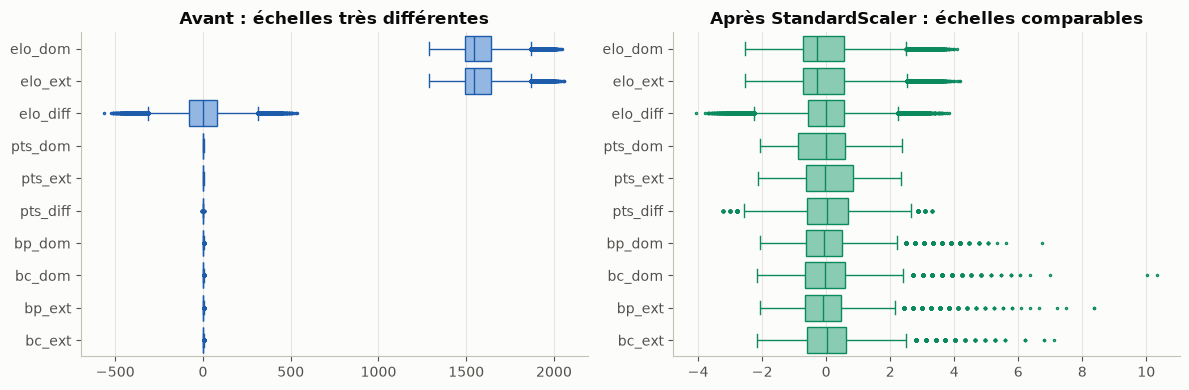

,moyenne brute,écart-type brut,moyenne standardisée,écart-type standardisé,min MinMax,max MinMax
elo_dom,1577.74,115.59,-0.0,1.0,0.0,1.0
elo_ext,1577.32,115.52,-0.0,1.0,0.0,1.0
elo_diff,0.43,139.51,-0.0,1.0,0.0,1.0
pts_dom,1.40,0.67,0.0,1.0,0.0,1.0
pts_ext,1.43,0.67,-0.0,1.0,0.0,1.0
pts_diff,-0.04,0.92,0.0,1.0,0.0,1.0
bp_dom,1.45,0.70,-0.0,1.0,0.0,1.0
bc_dom,1.42,0.66,-0.0,1.0,0.0,1.0
bp_ext,1.47,0.71,-0.0,1.0,0.0,1.0
bc_ext,1.39,0.65,-0.0,1.0,0.0,1.0


In [32]:
from sklearn.preprocessing import MinMaxScaler
brut = X.loc[X_train.index, num]                                           # train avant normalisation
mm_ = pd.DataFrame(MinMaxScaler().fit_transform(brut), columns=num)
cmp_ = pd.DataFrame({'moyenne brute': brut.mean(), 'écart-type brut': brut.std(),
                     'moyenne standardisée': X_train[num].mean(), 'écart-type standardisé': X_train[num].std(),
                     'min MinMax': mm_.min(), 'max MinMax': mm_.max()}).round(2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=brut, orient='h', color='#86b6ef', linecolor='#1c5cab', fliersize=1.5, ax=axes[0]); axes[0].set_title('Avant : échelles très différentes')
sns.boxplot(data=X_train[num], orient='h', color='#7fd6b6', linecolor='#0b8a5f', fliersize=1.5, ax=axes[1]); axes[1].set_title('Après StandardScaler : échelles comparables')
plt.tight_layout(); plt.show()
cmp_

## 6. Modélisation (Ch.5)
On compare **3 modèles** : régression logistique (simple), arbre de décision (profondeur limitée contre le sur-apprentissage) et forêt aléatoire (plusieurs arbres).

In [33]:
modeles = {
    'Régression logistique': LogisticRegression(max_iter=2000),
    'Arbre de décision': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Forêt aléatoire': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1),
}
res = []
for nom, m in modeles.items():                        # entraînement + évaluation de chaque modèle
    m.fit(X_train, y_train)                           # apprentissage
    p = m.predict(X_test)                             # prédictions sur le test
    res.append([nom, accuracy_score(y_train, m.predict(X_train)), accuracy_score(y_test, p), f1_score(y_test, p, average='macro')])
res = pd.DataFrame(res, columns=['Modèle', 'Accuracy train', 'Accuracy test', 'F1 macro test'])
print('Référence (toujours victoire domicile) :', round(reference, 3))
res.round(3)

Référence (toujours victoire domicile) : 0.452


,Modèle,Accuracy train,Accuracy test,F1 macro test
0,Régression logistique,0.532,0.532,0.387
1,Arbre de décision,0.531,0.528,0.386
2,Forêt aléatoire,0.584,0.535,0.393


## 7. Évaluation (Ch.6)
Matrice de confusion et rapport par classe (précision, rappel, F1) du meilleur modèle.

In [34]:
meilleur = res.sort_values('Accuracy test').iloc[-1]['Modèle']   # meilleur modèle selon l'exactitude test
m = modeles[meilleur]; p = m.predict(X_test)
print('Meilleur modèle :', meilleur)
print(classification_report(y_test, p, target_names=['Victoire ext.', 'Nul', 'Victoire dom.'], zero_division=0))

Meilleur modèle : Forêt aléatoire
               precision    recall  f1-score   support

Victoire ext.       0.51      0.52      0.52      5133
          Nul       0.37      0.00      0.01      3640
Victoire dom.       0.55      0.81      0.65      7236

     accuracy                           0.54     16009
    macro avg       0.48      0.45      0.39     16009
 weighted avg       0.50      0.54      0.46     16009



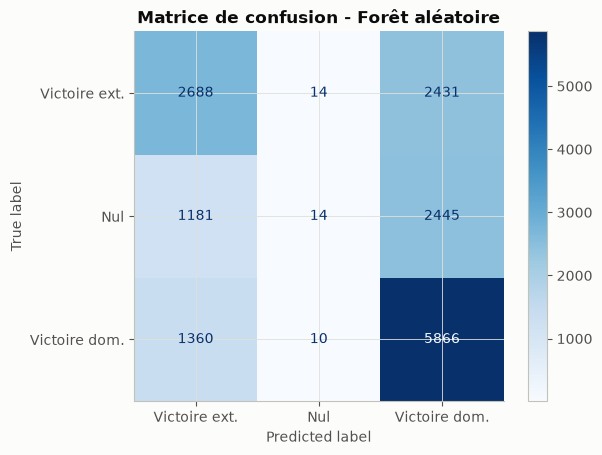

In [35]:
ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=['Victoire ext.', 'Nul', 'Victoire dom.'], cmap='Blues')   # matrice de confusion
plt.title('Matrice de confusion - ' + meilleur); plt.show()

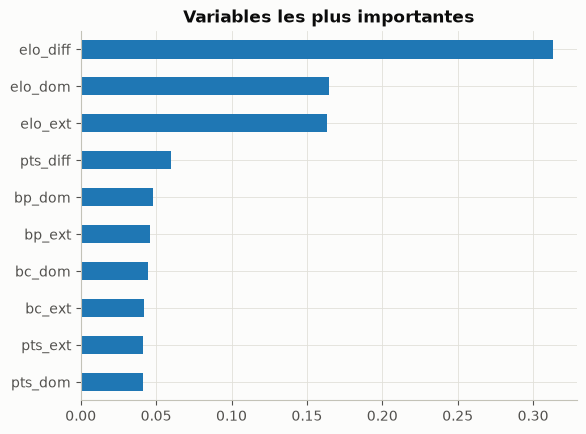

In [36]:
rf = modeles['Forêt aléatoire']                                   # importance des variables (forêt)
pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(10).plot(kind='barh', title='Variables les plus importantes')
plt.show()

In [37]:
ex = X_test.tail(50).index                                          # 8 matchs du test
proba = pd.DataFrame(m.predict_proba(X_test.loc[ex]), index=ex, columns=['P(ext.)', 'P(nul)', 'P(dom.)']).round(2)  # probabilités
noms = {0: 'Victoire ext.', 1: 'Nul', 2: 'Victoire dom.'}
pd.concat([df.loc[ex, ['home_club_name', 'away_club_name']], proba,
           y_test.loc[ex].map(noms).rename('Réel'), pd.Series(m.predict(X_test.loc[ex]), index=ex).map(noms).rename('Prédit')], axis=1)

,home_club_name,away_club_name,P(ext.),P(nul),P(dom.),Réel,Prédit
27458,Willem II Tilburg,AZ Alkmaar,0.49,0.30,0.21,Nul,Victoire ext.
62599,Celtic FC,Motherwell FC,0.04,0.09,0.86,Nul,Victoire dom.
22885,Sporting Gijón,SD Eibar,0.26,0.27,0.47,Victoire dom.,Victoire dom.
43128,Queen of the South FC,Queen's Park FC,0.50,0.10,0.40,Victoire ext.,Victoire ext.
12404,HNK Rijeka,FC Sheriff Tiraspol,0.30,0.18,0.52,Victoire dom.,Victoire dom.
40094,FC Barcelona,Liverpool FC,0.27,0.18,0.55,Victoire dom.,Victoire dom.
45805,Hellas Verona,Società Sportiva Lazio S.p.A.,0.57,0.25,0.18,Victoire ext.,Victoire ext.
75460,Le Havre AC,FC Toulouse,0.43,0.24,0.33,Victoire ext.,Victoire ext.
80935,FC Nantes,Stade Rennais FC,0.39,0.25,0.36,Nul,Victoire ext.
34080,Sivasspor,Fenerbahce,0.59,0.23,0.18,Victoire ext.,Victoire ext.


**Interprétation** : le modèle bat la référence mais reste modeste : le football est très aléatoire (un but change tout). Il retrouve la plupart des victoires à domicile et environ la moitié des victoires à l'extérieur, mais **presque jamais le match nul** (classe floue, sans signal fort). La variable de loin la plus utile est la force Elo (écart entre les deux équipes), devant l'écart de forme. **Pistes** : ajouter la valeur marchande des effectifs (`player_valuations.csv`), le repos entre matchs, les confrontations directes.

## 8. Enrichissement avec les autres tables du jeu de données
On ajoute au modèle de nouvelles variables **calculées sans fuite d'information** (uniquement avec ce qui était connu *avant* chaque match) :
- **Valeur marchande de l'effectif à la date du match**, reconstruite avec `player_valuations.csv` (dernière valeur connue de chaque joueur, ignorée si elle a plus de 18 mois) ;
- **Jours de repos** de chaque équipe depuis son dernier match (fatigue / calendrier) ;
- le type de compétition (déjà présent) distingue aussi les **matchs de sélections nationales**.

On compare ensuite le modèle de base et le modèle enrichi avec **deux protocoles** : le découpage aléatoire de l'étape 5 et un **découpage temporel** (entraînement sur le passé, test sur les 20 % de matchs les plus récents), plus proche d'une vraie prédiction.

> Adapter `DOSSIER` si besoin. Exécuter d'abord toutes les cellules précédentes.

In [38]:
# ===== 8.1 Nouvelles variables issues des autres tables =====
import os
DOSSIER = globals().get('DATA_DIR', Path.cwd())

def lire_csv(nom, **kw):
    try:
        return pd.read_csv(DOSSIER / nom, **kw)
    except Exception as e:
        print(f"⚠️ {nom} non chargé ({type(e).__name__}) : les informations liées seront masquées.")
        return None

df['_date'] = pd.to_datetime(df['date'], errors='coerce')
SEL = 'national_team_competition'
est_sel = df['competition_type'].eq(SEL)

ids_sel = set(df.loc[est_sel, 'home_club_id']) | set(df.loc[est_sel, 'away_club_id'])
ids_clu = set(df.loc[~est_sel, 'home_club_id']) | set(df.loc[~est_sel, 'away_club_id'])
print(f"{len(ids_clu)} clubs · {len(ids_sel)} sélections nationales · {len(ids_sel & ids_clu)} identifiant(s) en commun")
if ids_sel & ids_clu:
    print("⚠️ Des identifiants sont partagés : l'Elo et la forme mélangent ces équipes.")

val = lire_csv('player_valuations.csv', usecols=['player_id', 'date', 'market_value_in_eur', 'current_club_id'])
if val is None:
    val = pd.DataFrame({'player_id': [], 'date': [], 'market_value_in_eur': [], 'current_club_id': []})
val = val.dropna().assign(date=lambda d: pd.to_datetime(d['date'], errors='coerce')).dropna()
val = val.sort_values('date').reset_index(drop=True)
vd, vp = val['date'].values, val['player_id'].values
vv, vc = val['market_value_in_eur'].astype(float).values, val['current_club_id'].values
FEN = np.timedelta64(540, 'D')

total_club, dernier, dernier_match = {}, {}, {}
i_ev = i_exp = 0
vh, va, rh, ra = [], [], [], []
dates = df['_date'].values
for t, h, a, s in zip(dates, df['home_club_id'].values, df['away_club_id'].values, est_sel.values):
    while i_ev < len(vd) and vd[i_ev] < t:
        p = vp[i_ev]
        if p in dernier:
            total_club[vc[dernier[p]]] -= vv[dernier[p]]
        dernier[p] = i_ev
        total_club[vc[i_ev]] = total_club.get(vc[i_ev], 0.0) + vv[i_ev]
        i_ev += 1
    while i_exp < i_ev and vd[i_exp] < t - FEN:
        p = vp[i_exp]
        if dernier.get(p) == i_exp:
            total_club[vc[i_exp]] -= vv[i_exp]
            del dernier[p]
        i_exp += 1
    x, z = total_club.get(h, 0.0), total_club.get(a, 0.0)
    vh.append(np.nan if s or x <= 0 else x)
    va.append(np.nan if s or z <= 0 else z)
    for lst, club in ((rh, h), (ra, a)):
        d0 = dernier_match.get((s, club))
        lst.append(30.0 if d0 is None else float(min(30, (t - d0) / np.timedelta64(1, 'D'))))
    dernier_match[(s, h)] = t
    dernier_match[(s, a)] = t

date_fin = dates.max()

def variables_valeur(x, z):
    x, z = np.asarray(x, float), np.asarray(z, float)
    ok = ~np.isnan(x) & ~np.isnan(z)
    lx, lz = np.log10(np.where(ok, x, 1.0)), np.log10(np.where(ok, z, 1.0))
    return np.where(ok, lx - lz, 0.0), np.where(ok, (lx + lz) / 2, 7.0), ok.astype(int)

df['val_dom_eur'], df['val_ext_eur'] = vh, va
df['val_diff'], df['val_moy'], df['val_connue'] = variables_valeur(vh, va)
df['repos_dom'], df['repos_ext'] = rh, ra
print(f"Valeur d'effectif connue pour {df['val_connue'].mean():.1%} des matchs · repos moyen : {np.mean(rh):.1f} jours")

extra = ['val_diff', 'val_moy', 'repos_dom', 'repos_ext']
num2 = num + extra
X2 = pd.get_dummies(df[num2 + ['val_connue', 'competition_type']], columns=['competition_type'], drop_first=True, dtype=int)
print(X.shape, '->', X2.shape)

1759 clubs · 66 sélections nationales · 0 identifiant(s) en commun
Valeur d'effectif connue pour 94.6% des matchs · repos moyen : 9.3 jours
(80044, 14) -> (80044, 19)


In [39]:
# ===== 8.2 Comparaison : modèle de base vs modèle enrichi (découpage aléatoire et temporel) =====
from sklearn.ensemble import HistGradientBoostingClassifier

def modeles_neufs():
    return {'Régression logistique': LogisticRegression(max_iter=2000),
            'Arbre de décision': DecisionTreeClassifier(max_depth=5, random_state=42),
            'Forêt aléatoire': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1),
            'Gradient boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42)}

def ajuster(Xj, numj, tr, te, mod):                       # normalisation sur le train uniquement, apprentissage, prédiction sur le test
    A, B = Xj.loc[tr].copy(), Xj.loc[te].copy()
    s = StandardScaler().fit(A[numj]); A[numj] = s.transform(A[numj]); B[numj] = s.transform(B[numj])
    mod.fit(A, y.loc[tr])
    return mod, s, mod.predict(B)

tr_a, te_a = X_train.index, X_test.index                  # découpage aléatoire de l'étape 5 (mêmes matchs pour comparer)
coupe = int(len(df) * 0.8)
tr_t, te_t = df.index[:coupe], df.index[coupe:]           # découpage temporel : 80 % les plus anciens / 20 % les plus récents

res2, ajustes = [], {}
for jeu, (Xj, numj) in {'Base': (X, num), 'Enrichi': (X2, num2)}.items():
    mods_a, mods_t = modeles_neufs(), modeles_neufs()
    for nom in mods_a:
        ma, sa, pa = ajuster(Xj, numj, tr_a, te_a, mods_a[nom])
        _, _, pt = ajuster(Xj, numj, tr_t, te_t, mods_t[nom])
        ajustes[(jeu, nom)] = (ma, sa)                    # on garde les modèles entraînés sur le découpage aléatoire
        res2.append([jeu, nom, accuracy_score(y.loc[te_a], pa), accuracy_score(y.loc[te_t], pt), f1_score(y.loc[te_t], pt, average='macro')])
res2 = pd.DataFrame(res2, columns=['Variables', 'Modèle', 'Accuracy (test aléatoire)', 'Accuracy (test temporel)', 'F1 macro (test temporel)'])

meilleur2 = res2[res2['Variables'] == 'Enrichi'].sort_values('Accuracy (test temporel)').iloc[-1]['Modèle']   # choix sur le test temporel
modele2, sc2 = ajustes[('Enrichi', meilleur2)]
ref_t = y.loc[te_t].value_counts(normalize=True).max()
b = res2[res2['Variables'] == 'Base']['Accuracy (test temporel)'].max()
e = res2[res2['Variables'] == 'Enrichi']['Accuracy (test temporel)'].max()
print(f"Référence (toujours la classe majoritaire, test temporel) : {ref_t:.3f}")
print(f"Meilleur modèle enrichi : {meilleur2}")
print(f"Meilleure accuracy temporelle : base {b:.3f} -> enrichi {e:.3f} ({(e - b) * 100:+.1f} point)")
res2.round(3)

Référence (toujours la classe majoritaire, test temporel) : 0.445
Meilleur modèle enrichi : Régression logistique
Meilleure accuracy temporelle : base 0.517 -> enrichi 0.524 (+0.7 point)


,Variables,Modèle,Accuracy (test aléatoire),Accuracy (test temporel),F1 macro (test temporel)
0,Base,Régression logistique,0.532,0.517,0.375
1,Base,Arbre de décision,0.528,0.516,0.373
2,Base,Forêt aléatoire,0.535,0.516,0.378
3,Base,Gradient boosting,0.531,0.517,0.377
4,Enrichi,Régression logistique,0.540,0.524,0.382
5,Enrichi,Arbre de décision,0.534,0.519,0.381
6,Enrichi,Forêt aléatoire,0.540,0.522,0.383
7,Enrichi,Gradient boosting,0.540,0.523,0.385


## 8 bis. Évaluation et réglage (Ch.5-6) : réitérer jusqu'à ce que les performances soient satisfaisantes
Boucle de la chaîne ML : on **règle les hyperparamètres** avec une validation croisée **temporelle** (`TimeSeriesSplit` : on apprend toujours sur le passé et on valide sur le futur), on trace la **courbe de validation**, puis on évalue **une seule fois** sur le test temporel. Le modèle est un **Pipeline complet** (normalisation + encodage + classifieur) : c'est lui qu'on déploiera au §10, ce qui évite tout écart entre entraînement et service.

In [40]:
# ===== 8 bis.1 Pipeline complet + recherche d'hyperparamètres (GridSearch et RandomizedSearch) =====
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, validation_curve
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

CAT, BIN = ['competition_type'], ['val_connue']
FEATURES = num2 + BIN + CAT                                   # contrat d'entrée du modèle (réutilisé pour l'API)
LABELS = ['Victoire extérieur', 'Nul', 'Victoire domicile']   # classes 0, 1, 2

def preprocess():                                             # même prétraitement à l'entraînement et en production
    return ColumnTransformer([('num', StandardScaler(), num2), ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)], remainder='passthrough')

Xa, ya = df.loc[tr_t, FEATURES], y.loc[tr_t]                  # passé (80 %)
Xb, yb = df.loc[te_t, FEATURES], y.loc[te_t]                  # futur (20 %) : touché une seule fois, à la fin
cv = TimeSeriesSplit(n_splits=4)

espaces = {
    'Régression logistique': (LogisticRegression(max_iter=2000), {'clf__C': [0.01, 0.1, 1, 10]}),
    'Gradient boosting': (HistGradientBoostingClassifier(random_state=42),
                          {'clf__max_depth': [2, 3, 4], 'clf__learning_rate': [0.03, 0.05, 0.1], 'clf__max_iter': [100, 200], 'clf__min_samples_leaf': [20, 50]}),
}
recherches, lignes = {}, []
for nom, (est, grille) in espaces.items():
    pipe = Pipeline([('prep', preprocess()), ('clf', est)])
    if nom == 'Gradient boosting':                            # espace plus grand -> recherche aléatoire (8 tirages)
        rech = RandomizedSearchCV(pipe, grille, n_iter=8, cv=cv, scoring='accuracy', random_state=42, n_jobs=-1)
    else:                                                     # petit espace -> grille complète
        rech = GridSearchCV(pipe, grille, cv=cv, scoring='accuracy', n_jobs=-1)
    rech.fit(Xa, ya)
    recherches[nom] = rech
    lignes.append([nom, {k.replace('clf__', ''): v for k, v in rech.best_params_.items()}, rech.best_score_,
                   accuracy_score(ya, rech.predict(Xa)), accuracy_score(yb, rech.predict(Xb))])
tab = pd.DataFrame(lignes, columns=['Modèle', 'Meilleurs hyperparamètres', 'Accuracy CV (passé)', 'Accuracy train', 'Accuracy test temporel'])
nom_final = tab.sort_values('Accuracy CV (passé)').iloc[-1]['Modèle']          # choix sur la validation croisée, PAS sur le test
modele_final = recherches[nom_final].best_estimator_
print('Modèle retenu (meilleure validation croisée) :', nom_final, '| référence test :', round(ref_t, 3))
tab.round(3)

Modèle retenu (meilleure validation croisée) : Régression logistique | référence test : 0.445


,Modèle,Meilleurs hyperparamètres,Accuracy CV (passé),Accuracy train,Accuracy test temporel
0,Régression logistique,{'C': 0.1},0.543,0.541,0.524
1,Gradient boosting,"{'min_samples_leaf': 50, 'max_iter': 200, 'max...",0.543,0.546,0.523


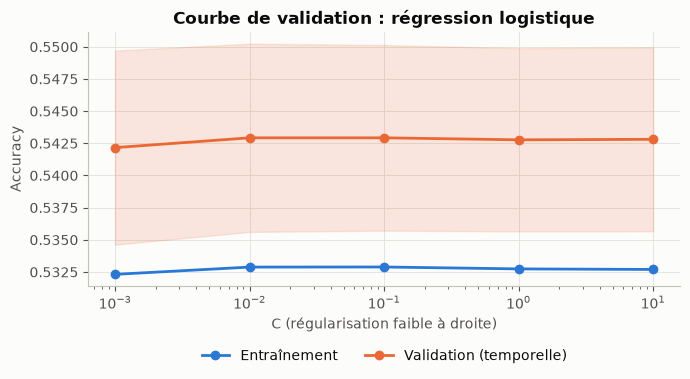

Les deux courbes sont plates : la régularisation change peu le résultat et la validation n'est pas inférieure à l'entraînement -> pas de surapprentissage. Le plafond vient des variables, pas du réglage (voir §8).


In [41]:
# ===== 8 bis.2 Courbe de validation : sous-apprentissage / surapprentissage selon C (régression logistique) =====
Cs = np.logspace(-3, 1, 5)
pipe_lr = Pipeline([('prep', preprocess()), ('clf', LogisticRegression(max_iter=2000))])
tr_sc, va_sc = validation_curve(pipe_lr, Xa, ya, param_name='clf__C', param_range=Cs, cv=cv, scoring='accuracy', n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Cs, tr_sc.mean(axis=1), color='#2a78d6', lw=2, marker='o', label='Entraînement')
ax.plot(Cs, va_sc.mean(axis=1), color='#eb6834', lw=2, marker='o', label='Validation (temporelle)')
ax.fill_between(Cs, va_sc.mean(axis=1) - va_sc.std(axis=1), va_sc.mean(axis=1) + va_sc.std(axis=1), color='#eb6834', alpha=0.15)
ax.set_xscale('log'); ax.set(title='Courbe de validation : régression logistique', xlabel='C (régularisation faible à droite)', ylabel='Accuracy')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2); plt.tight_layout(); plt.show()
print('Les deux courbes sont plates : la régularisation change peu le résultat et la validation n\'est pas inférieure à l\'entraînement -> pas de surapprentissage. Le plafond vient des variables, pas du réglage (voir §8).')

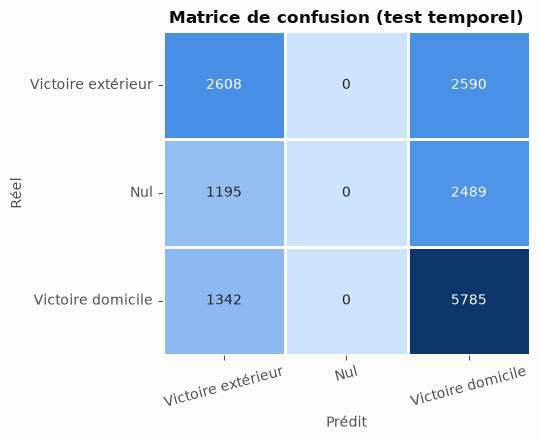

Accuracy test temporel : 0.524 | référence (classe majoritaire) : 0.445 | F1 macro : 0.382


,Classe,Précision,Rappel,Spécificité,F1
0,Victoire extérieur,0.507,0.502,0.765,0.504
1,Nul,0.000,0.000,1.000,0.000
2,Victoire domicile,0.532,0.812,0.428,0.643


In [42]:
# ===== 8 bis.3 Évaluation finale (Ch.6) : matrice de confusion et métriques par classe sur le test temporel =====
pf = modele_final.predict(Xb)
cm = confusion_matrix(yb, pf)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap=SEQ, xticklabels=LABELS, yticklabels=LABELS, linewidths=2, linecolor='#fcfcfb', cbar=False, ax=ax)
ax.set(title='Matrice de confusion (test temporel)', xlabel='Prédit', ylabel='Réel'); ax.grid(False); plt.xticks(rotation=15); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

pr, rc, f1, _ = precision_recall_fscore_support(yb, pf, labels=[0, 1, 2], zero_division=0)
spec = [cm.sum() - cm[i].sum() - cm[:, i].sum() + cm[i, i] for i in range(3)]               # vrais négatifs
spec = [s / (s + (cm[:, i].sum() - cm[i, i])) for i, s in enumerate(spec)]                   # spécificité = VN / (VN + FP)
rap = pd.DataFrame({'Classe': LABELS, 'Précision': pr, 'Rappel': rc, 'Spécificité': spec, 'F1': f1}).round(3)
print(f"Accuracy test temporel : {accuracy_score(yb, pf):.3f} | référence (classe majoritaire) : {ref_t:.3f} | F1 macro : {f1_score(yb, pf, average='macro'):.3f}")
rap

**Lecture** : on compare toujours à la référence « classe majoritaire ». Le « nul » n'est presque jamais prédit (rappel ≈ 0) : c'est le plafond naturel du football (un nul ressemble à un match équilibré), pas un bug ; le modèle sert surtout à départager domicile / extérieur. Si la performance n'est pas jugée satisfaisante, on réitère (nouvelles variables au §8, nouvelle grille ici) ; sinon on passe au déploiement.

## 9. Interface professionnelle de prédiction
Tableau de bord interactif : on choisit l'**équipe 1 (domicile)** et l'**équipe 2 (extérieur)** (clubs ou sélections nationales), puis un **match réel** (comparaison prédiction / résultat réel) ou un **match hypothétique** (état actuel des équipes).

Il utilise le modèle enrichi de la section 8 et affiche, selon les tables disponibles : probabilités, forme, Elo, valeur de l'effectif, jours de repos, fiche du club (`clubs.csv`) ou de la sélection (`national_teams.csv`), confrontations directes et contexte du match (`games.csv`, `competitions.csv`).

> Prérequis (une seule fois) : `pip install ipywidgets`. Si un fichier est introuvable, les blocs correspondants sont simplement masqués.

In [43]:
# ===== 9.1 Données d'affichage et fonctions utilitaires =====
import html as _h
import ipywidgets as widgets
from IPython.display import display

clubs, compets, nationales = lire_csv('clubs.csv'), lire_csv('competitions.csv'), lire_csv('national_teams.csv')
fiche_club = clubs.drop_duplicates('club_id').set_index('club_id') if clubs is not None else None
fiche_sel = nationales.drop_duplicates('national_team_id').set_index('national_team_id') if nationales is not None else None
nom_comp = {}
if compets is not None:                                   # « bundesliga » existe en Allemagne et en Autriche -> on ajoute le pays
    for cid_, nm_, pays_ in zip(compets['competition_id'], compets['name'], compets['country_name']):
        nom_comp[cid_] = str(nm_).replace('-', ' ').title() + (f" ({pays_})" if pd.notna(pays_) else '')

modele, sc_i, X_i, num_i = modele2, sc2, X2, num2          # modèle enrichi utilisé par l'interface
acc_alea = res2[(res2['Variables'] == 'Enrichi') & (res2['Modèle'] == meilleur2)]['Accuracy (test aléatoire)'].iloc[0]
acc_temp = res2[(res2['Variables'] == 'Enrichi') & (res2['Modèle'] == meilleur2)]['Accuracy (test temporel)'].iloc[0]
etiq = {0: 'Victoire extérieur', 1: 'Nul', 2: 'Victoire domicile'}
LIB_COMP = {'domestic_league': 'Championnat national', 'domestic_cup': 'Coupe nationale', 'international_cup': 'Coupe internationale',
            SEL: 'Compétition de sélections', 'other': 'Autre'}
COUL = {'V': '#16a34a', 'N': '#94a3b8', 'D': '#dc2626'}
C_DOM, C_NUL, C_EXT = '#2563eb', '#94a3b8', '#f59e0b'

# --- équipes disponibles (nom -> identifiant), séparées en clubs / sélections ---
tous = pd.concat([df[['home_club_id', 'home_club_name']].set_axis(['id', 'nom'], axis=1),
                  df[['away_club_id', 'away_club_name']].set_axis(['id', 'nom'], axis=1)]).dropna().drop_duplicates('nom')
club_id = dict(zip(tous['nom'], tous['id']))
liste_tous = sorted(club_id)
liste_sel = sorted(n for n, i in club_id.items() if i in ids_sel and i not in ids_clu)
liste_clu = sorted(n for n in club_id if n not in set(liste_sel))
types_comp = sorted(df['competition_type'].unique())

# --- petits utilitaires d'affichage ---
def esc(x): return _h.escape(str(x))
def valeur(r, col, defaut='—'):
    if r is None or col not in r.index or pd.isna(r[col]): return defaut
    return r[col]
def nombre(v, fmt='{:.0f}'):
    try: return fmt.format(float(v))
    except (TypeError, ValueError): return '—'
def eur(v):
    try: v = float(v)
    except (TypeError, ValueError): return '—'
    if pd.isna(v): return '—'
    return f"{v/1e9:.2f} Md €" if v >= 1e9 else (f"{v/1e6:.1f} M €" if v >= 1e6 else f"{v/1e3:.0f} k €")
def nom_competition(cid): return nom_comp.get(cid, str(cid))

# --- historique avant une date donnée ---
def derniers(club, date, n=5):                            # n derniers résultats d'une équipe avant 'date'
    d = df[((df['home_club_id'] == club) | (df['away_club_id'] == club)) & (df['_date'] < date)].sort_values('_date').tail(n)
    out = []
    for r in d.itertuples():
        dom = r.home_club_id == club
        gf, gc = (r.home_club_goals, r.away_club_goals) if dom else (r.away_club_goals, r.home_club_goals)
        out.append(('V' if gf > gc else 'N' if gf == gc else 'D', int(gf), int(gc),
                    r.away_club_name if dom else r.home_club_name, dom, str(r.date)[:10]))
    return out

def face_a_face(h, a, date):                              # confrontations directes (dans les deux sens) avant 'date'
    m = ((df['home_club_id'] == h) & (df['away_club_id'] == a)) | ((df['home_club_id'] == a) & (df['away_club_id'] == h))
    return df[m & (df['_date'] < date)].sort_values('_date', ascending=False)

# --- ligne de variables d'un match hypothétique (état le plus récent des données) ---
def ligne_hypothetique(h, a, comp):
    sel = comp == SEL
    fh, fa = forme(hist[h]), forme(hist[a])                # [nb, points, buts pour, buts contre]
    v = pd.Series(0.0, index=list(X_i.columns) + ['val_dom_eur', 'val_ext_eur'])
    v['elo_dom'], v['elo_ext'], v['elo_diff'] = elo[h], elo[a], elo[h] - elo[a]
    v['pts_dom'], v['bp_dom'], v['bc_dom'] = fh[1], fh[2], fh[3]
    v['pts_ext'], v['bp_ext'], v['bc_ext'] = fa[1], fa[2], fa[3]
    v['pts_diff'] = fh[1] - fa[1]
    xh, xa = (np.nan if sel else (total_club.get(h, 0.0) or np.nan)), (np.nan if sel else (total_club.get(a, 0.0) or np.nan))
    v['val_dom_eur'], v['val_ext_eur'] = xh, xa
    d_, m_, c_ = variables_valeur(xh, xa)
    v['val_diff'], v['val_moy'], v['val_connue'] = float(d_), float(m_), float(c_)
    for col, club in (('repos_dom', h), ('repos_ext', a)):  # jours depuis le dernier match, au lendemain de la dernière date des données
        d0 = dernier_match.get((sel, club))
        v[col] = 30.0 if d0 is None else float(min(30, (date_fin - d0) / np.timedelta64(1, 'D') + 1))
    if 'competition_type_' + comp in v.index: v['competition_type_' + comp] = 1.0
    return v

# --- feuille de style (fond blanc explicite : lisible en thème clair comme sombre) ---
CSS = """<style>
.fp{font-family:'Segoe UI',system-ui,-apple-system,Roboto,sans-serif;color:#1f2937;line-height:1.35;max-width:900px}
.fp *{box-sizing:border-box}
.fp-head{background:linear-gradient(120deg,#0b1f3a,#1d4e89);color:#fff;border-radius:12px;padding:14px 18px;display:flex;justify-content:space-between;align-items:center;flex-wrap:wrap;gap:10px}
.fp-head h2{margin:0;font-size:20px;color:#fff}
.fp-head small{opacity:.85;display:block;margin-top:2px}
.fp-kpis{display:flex;gap:10px;flex-wrap:wrap}
.fp-kpi{background:rgba(255,255,255,.14);border-radius:8px;padding:6px 12px;text-align:center;min-width:96px}
.fp-kpi b{display:block;font-size:17px}
.fp-kpi span{font-size:11px;opacity:.85}
.fp-card{background:#fff;border:1px solid #e5e7eb;border-radius:12px;padding:14px 16px;margin:10px 0;box-shadow:0 1px 3px rgba(0,0,0,.06);color:#1f2937}
.fp-grid{display:flex;gap:12px;flex-wrap:wrap}
.fp-grid>.fp-card{flex:1 1 320px;margin:0}
.fp-match{display:flex;align-items:center;justify-content:space-between;gap:10px;text-align:center}
.fp-team{flex:1;font-size:20px;font-weight:700;color:#111827}
.fp-team small{display:block;font-size:12px;font-weight:400;color:#6b7280}
.fp-vs{font-weight:700;color:#9ca3af}
.fp-sub{text-align:center;color:#6b7280;font-size:13px;margin-top:8px}
.fp-bar{display:flex;height:30px;border-radius:8px;overflow:hidden;margin:12px 0 6px}
.fp-bar div{display:flex;align-items:center;justify-content:center;color:#fff;font-size:12px;font-weight:600;overflow:hidden;white-space:nowrap}
.fp-leg{display:flex;justify-content:space-between;font-size:12px;color:#6b7280}
.fp-boxes{display:flex;gap:12px;flex-wrap:wrap;margin-top:12px}
.fp-box{flex:1 1 220px;border-radius:10px;padding:12px;text-align:center;background:#f3f4f6}
.fp-box .t{font-size:11px;color:#6b7280;text-transform:uppercase;letter-spacing:.05em}
.fp-box .v{font-size:19px;font-weight:700;margin-top:4px;color:#111827}
.fp-box .s{font-size:12px;color:#6b7280;margin-top:2px}
.fp-verdict{border-radius:10px;padding:10px 14px;margin-top:12px;font-weight:600}
.fp-ok{background:#dcfce7;color:#166534}.fp-ko{background:#fee2e2;color:#991b1b}.fp-neutre{background:#e0f2fe;color:#075985}.fp-warn{background:#fef3c7;color:#92400e}
.fp table{width:100%;border-collapse:collapse;font-size:14px}
.fp td{padding:6px 4px;border-bottom:1px solid #f1f5f9;color:#1f2937}
.fp td:first-child{color:#6b7280;width:46%}
.fp h4{margin:0 0 10px;font-size:15px;color:#111827}
.fp-pill{display:inline-block;width:26px;height:26px;line-height:26px;text-align:center;border-radius:50%;color:#fff;font-weight:700;font-size:12px;margin-right:4px;cursor:default}
.fp-note{color:#6b7280;font-size:12px;margin-top:8px}
</style>"""
def page(contenu): return CSS + f"<div class='fp'>{contenu}</div>"
def carte(contenu): return f"<div class='fp-card'>{contenu}</div>"
def pastilles(lst):
    if not lst: return "<span style='color:#94a3b8'>Aucun match</span>"
    return ''.join(f"<span class='fp-pill' style='background:{COUL[r]}' title='{esc(d)} · {'dom.' if dom else 'ext.'} vs {esc(adv)} · {gf}-{gc}'>{r}</span>"
                   for r, gf, gc, adv, dom, d in lst)

In [44]:
# ===== 9.2 Interface : rendu des onglets et widgets =====
bilan = {'ok': 0, 'n': 0, 'vus': set()}                   # bilan de la session (matchs réels déjà testés, comptés une seule fois)
set_train = set(tr_a)

def entete():
    taux = f"{100*bilan['ok']/bilan['n']:.0f} %" if bilan['n'] else '—'
    sess = f"{bilan['ok']}/{bilan['n']}" if bilan['n'] else '—'
    return page(f"""<div class='fp-head'><div><h2>⚽ Football Match Predictor</h2>
      <small>Modèle : {esc(meilleur2)} · variables enrichies · {len(df):,} matchs analysés</small></div>
      <div class='fp-kpis'>
        <div class='fp-kpi'><b>{acc_alea*100:.1f} %</b><span>Précision (test aléatoire)</span></div>
        <div class='fp-kpi'><b>{acc_temp*100:.1f} %</b><span>Précision (test temporel)</span></div>
        <div class='fp-kpi'><b>{ref_t*100:.1f} %</b><span>Référence</span></div>
        <div class='fp-kpi'><b>{sess}</b><span>Session · {taux}</span></div>
      </div></div>""".replace(',', ' '))

def onglet_prediction(hn, an, v, pr, pred, reel, r, vu):
    P = dict(zip(modele.classes_, pr))
    bar = ''.join(f"<div style='width:{P[c]*100:.1f}%;background:{col}'>{P[c]*100:.0f} %</div>"
                  for c, col in [(2, C_DOM), (1, C_NUL), (0, C_EXT)] if P[c] > 0.04)
    sous = (f"{str(r['date'])[:10]} · {esc(nom_competition(r['competition_id']))}" if r is not None
            else "Match hypothétique · état le plus récent des données")
    haut = carte(f"""<div class='fp-match'><div class='fp-team'>{esc(hn)}<small>Domicile · Elo {v['elo_dom']:.0f}</small></div>
        <div class='fp-vs'>VS</div><div class='fp-team'>{esc(an)}<small>Extérieur · Elo {v['elo_ext']:.0f}</small></div></div>
        <div class='fp-sub'>{sous}</div>
        <div class='fp-bar'>{bar}</div>
        <div class='fp-leg'><span style='color:{C_DOM}'>■ Victoire domicile {P[2]*100:.1f} %</span>
        <span>■ Nul {P[1]*100:.1f} %</span><span style='color:{C_EXT}'>■ Victoire extérieur {P[0]*100:.1f} %</span></div>""")
    boite_pred = f"<div class='fp-box'><div class='t'>Prédiction du modèle</div><div class='v'>{etiq[pred]}</div><div class='s'>Confiance : {max(pr)*100:.1f} %</div></div>"
    if reel is None:
        boite_reel = "<div class='fp-box'><div class='t'>Résultat réel</div><div class='v'>—</div><div class='s'>Match hypothétique</div></div>"
        verdict = "<div class='fp-verdict fp-neutre'>ℹ️ Prédiction seule : aucun résultat réel à comparer.</div>"
    else:
        gh, ga = int(r['home_club_goals']), int(r['away_club_goals'])
        boite_reel = f"<div class='fp-box'><div class='t'>Résultat réel</div><div class='v'>{etiq[reel]}</div><div class='s'>Score : {gh} – {ga}</div></div>"
        quand = "jeu d'entraînement (déjà vu par le modèle)" if vu == 'train' else "jeu de test (jamais vu par le modèle)"
        if pred == reel:
            verdict = f"<div class='fp-verdict fp-ok'>✅ Prédiction correcte <span style='font-weight:400'>· match du {quand}</span></div>"
        else:
            verdict = (f"<div class='fp-verdict fp-ko'>❌ Prédiction incorrecte : prédit « {etiq[pred]} », réel « {etiq[reel]} » "
                       f"<span style='font-weight:400'>· match du {quand}</span></div>")
    return page(haut + carte(f"<div class='fp-boxes'>{boite_pred}{boite_reel}</div>{verdict}"))

def carte_club(cid, nom, role, v, suf, date_ref, couleur, sel):
    info = None
    if sel and fiche_sel is not None and cid in fiche_sel.index: info = fiche_sel.loc[cid]
    elif not sel and fiche_club is not None and cid in fiche_club.index: info = fiche_club.loc[cid]
    L = [('Elo (avant le match)', f"{v['elo_'+suf]:.0f}"), ('Points par match (5 derniers)', f"{v['pts_'+suf]:.2f}"),
         ('Buts marqués par match', f"{v['bp_'+suf]:.2f}"), ('Buts encaissés par match', f"{v['bc_'+suf]:.2f}"),
         ('Jours de repos', f"{v['repos_'+suf]:.0f}")]
    if pd.notna(v.get('val_' + suf + '_eur', np.nan)): L.append(("Valeur de l'effectif (à la date)", eur(v['val_' + suf + '_eur'])))
    if info is not None:
        L += [('Effectif · âge moyen', f"{nombre(valeur(info, 'squad_size'))} joueurs · {nombre(valeur(info, 'average_age'), '{:.1f}')} ans"),
              ('Joueurs étrangers', f"{nombre(valeur(info, 'foreigners_percentage'), '{:.0f}')} %"),
              ('Valeur marchande (actuelle)', eur(valeur(info, 'total_market_value')))]
        if sel:
            L += [('Classement FIFA', nombre(valeur(info, 'fifa_ranking'))), ('Sélectionneur', valeur(info, 'coach_name'))]
        else:
            if valeur(info, 'stadium_name') != '—':
                L.append(('Stade', f"{valeur(info, 'stadium_name')} ({nombre(valeur(info, 'stadium_seats'), '{:,.0f}').replace(',', ' ')} places)"))
            L.append(('Entraîneur', valeur(info, 'coach_name')))
    lignes = ''.join(f"<tr><td>{k}</td><td><b>{esc(x)}</b></td></tr>" for k, x in L if x != '—')
    return carte(f"<h4 style='border-left:4px solid {couleur};padding-left:8px'>{role} · {esc(nom)}</h4>"
                 f"<div style='margin-bottom:8px'>{pastilles(derniers(cid, date_ref))}</div><table>{lignes}</table>")

def onglet_clubs(h, a, hn, an, v, date_ref, sel):
    ok = (fiche_sel if sel else fiche_club) is not None
    note = ("Fiche (effectif, âge, valeur marchande actuelle, stade, entraîneur) : état actuel, pas à la date du match. " if ok
            else "Fichier de fiches non chargé : informations masquées. ")
    return page(f"<div class='fp-grid'>{carte_club(h, hn, 'Domicile', v, 'dom', date_ref, C_DOM, sel)}{carte_club(a, an, 'Extérieur', v, 'ext', date_ref, C_EXT, sel)}</div>"
                + carte(f"<div class='fp-note' style='margin-top:0'>Pastilles : 5 derniers résultats avant le match (V = victoire, N = nul, D = défaite). "
                        f"« Valeur de l'effectif » : somme des dernières valeurs connues des joueurs avant le match (player_valuations.csv). {note}</div>"))

def onglet_face_a_face(h, a, hn, an, date_ref):
    d = face_a_face(h, a, date_ref)
    if d.empty: return page(carte("<h4>🤝 Confrontations directes</h4>Aucune confrontation directe antérieure dans les données."))
    vh_ = vn_ = va_ = gh = ga = 0
    for r in d.itertuples():
        f, c = (r.home_club_goals, r.away_club_goals) if r.home_club_id == h else (r.away_club_goals, r.home_club_goals)
        gh += f; ga += c
        if f > c: vh_ += 1
        elif f == c: vn_ += 1
        else: va_ += 1
    n = len(d)
    bar = ''.join(f"<div style='width:{x/n*100:.1f}%;background:{col}'>{x}</div>" for x, col in [(vh_, C_DOM), (vn_, C_NUL), (va_, C_EXT)] if x)
    lignes = ''.join(f"<tr><td>{str(r.date)[:10]} · {esc(nom_competition(r.competition_id))}</td>"
                     f"<td><b>{esc(r.home_club_name)} {int(r.home_club_goals)} – {int(r.away_club_goals)} {esc(r.away_club_name)}</b></td></tr>"
                     for r in d.head(8).itertuples())
    return page(carte(f"""<h4>🤝 Confrontations directes ({n} match{'s' if n > 1 else ''})</h4>
        <div class='fp-bar'>{bar}</div>
        <div class='fp-leg'><span style='color:{C_DOM}'>■ {esc(hn)} : {vh_}</span><span>■ Nuls : {vn_}</span><span style='color:{C_EXT}'>■ {esc(an)} : {va_}</span></div>
        <div class='fp-sub'>Buts : {gh} – {ga} · moyenne {gh/n:.2f} – {ga/n:.2f} par match</div>""")
        + carte(f"<h4>Derniers matchs entre les deux équipes</h4><table>{lignes}</table>"))

def onglet_contexte(r):
    if r is None:
        return page(carte("<h4>🏟️ Contexte du match</h4>Match hypothétique : pas de contexte réel (stade, arbitre, affluence…)."))
    def deux(c1, c2, f='{}'):
        a_, b_ = r.get(c1), r.get(c2)
        return f"{f.format(a_)} — {f.format(b_)}" if pd.notna(a_) and pd.notna(b_) else None
    cand = [('Date', str(r['date'])[:10]), ('Compétition', nom_competition(r['competition_id'])), ('Saison', r.get('season')),
            ('Journée / tour', r.get('round')), ('Stade', r.get('stadium')),
            ('Affluence', nombre(r.get('attendance'), '{:,.0f}').replace(',', ' ') if pd.notna(r.get('attendance')) else None),
            ('Arbitre', r.get('referee')), ('Entraîneurs', deux('home_club_manager_name', 'away_club_manager_name')),
            ('Formations', deux('home_club_formation', 'away_club_formation')),
            ('Classement avant match', deux('home_club_position', 'away_club_position', '{:.0f}ᵉ'))]
    lignes = ''.join(f"<tr><td>{k}</td><td><b>{esc(x)}</b></td></tr>" for k, x in cand if x is not None and not pd.isna(x))
    return page(carte(f"<h4>🏟️ Contexte du match</h4><table>{lignes}</table>"
                      "<div class='fp-note'>Ces informations décrivent le match mais ne sont pas utilisées par le modèle.</div>"))

# --- widgets de saisie ---
Lw = lambda w: widgets.Layout(width=w)
tg = widgets.ToggleButtons(options=[('Tous', 'tous'), ('Clubs', 'clu'), ('Sélections nationales', 'sel')], value='tous',
                           description='Équipes :', style={'button_width': '140px'})
cb_dom = widgets.Combobox(options=liste_tous, placeholder='🏠 Équipe 1 (domicile) — tapez pour chercher', ensure_option=True, layout=Lw('435px'))
cb_ext = widgets.Combobox(options=liste_tous, placeholder='✈️ Équipe 2 (extérieur) — tapez pour chercher', ensure_option=True, layout=Lw('435px'))
HYPO = ('🔮 Match hypothétique (état le plus récent des deux équipes)', -1)
dd_match = widgets.Dropdown(options=[HYPO], value=-1, description='Match :', layout=Lw('880px'))
dd_comp = widgets.Dropdown(options=[(LIB_COMP.get(t, t), t) for t in types_comp],
                           value='domestic_league' if 'domestic_league' in types_comp else types_comp[0],
                           description='Compétition :', layout=Lw('435px'))
btn = widgets.Button(description='Prédire le match', button_style='primary', icon='bolt', layout=widgets.Layout(width='435px', height='34px'))
w_head = widgets.HTML(entete())
w_pred, w_clubs, w_h2h, w_ctx = (widgets.HTML() for _ in range(4))
tabs = widgets.Tab(children=[w_pred, w_clubs, w_h2h, w_ctx])
tabs.titles = ('🎯 Prédiction', '📊 Les deux équipes', '🤝 Confrontations', '🏟️ Contexte')

def avertir(texte):
    w_pred.value = page(carte(f"<div class='fp-verdict fp-warn' style='margin:0'>{texte}</div>"))
    w_clubs.value = w_h2h.value = w_ctx.value = ''

def maj_listes(*_):                                       # filtre Tous / Clubs / Sélections
    liste = {'tous': liste_tous, 'clu': liste_clu, 'sel': liste_sel}[tg.value]
    cb_dom.value = cb_ext.value = ''
    cb_dom.options = cb_ext.options = liste

def maj_matchs(*_):                                       # matchs réels entre les deux équipes (même sens dom./ext.)
    h, a = club_id.get(cb_dom.value), club_id.get(cb_ext.value)
    options = [HYPO]
    if h is not None and a is not None and h != a:
        d = df[(df['home_club_id'] == h) & (df['away_club_id'] == a)].sort_values('_date', ascending=False)
        options += [(f"{str(r.date)[:10]}  ·  {nom_competition(r.competition_id)}  ·  {int(r.home_club_goals)}–{int(r.away_club_goals)}", r.Index)
                    for r in d.itertuples()]
        deux_sel = cb_dom.value in liste_sel and cb_ext.value in liste_sel      # compétition par défaut du match hypothétique
        if deux_sel and SEL in types_comp: dd_comp.value = SEL
        elif not deux_sel and dd_comp.value == SEL: dd_comp.value = 'domestic_league' if 'domestic_league' in types_comp else types_comp[0]
    dd_match.options = options
    dd_match.value = options[1][1] if len(options) > 1 else -1

def predire(_):
    h, a = club_id.get(cb_dom.value), club_id.get(cb_ext.value)
    if h is None or a is None: return avertir('Choisissez les deux équipes dans la liste.')
    if h == a: return avertir('Les deux équipes doivent être différentes.')
    hn, an, idx = cb_dom.value, cb_ext.value, dd_match.value
    try:
        if idx == -1:                                     # match hypothétique
            sel = dd_comp.value == SEL
            v, r, reel, vu, date_ref = ligne_hypothetique(h, a, dd_comp.value), None, None, None, pd.Timestamp(date_fin) + pd.Timedelta(days=1)
        else:                                             # match réel
            r = df.loc[idx]; sel = r['competition_type'] == SEL
            v = pd.concat([X_i.loc[idx].astype(float), r[['val_dom_eur', 'val_ext_eur']].astype(float)])
            reel, vu, date_ref = int(y.loc[idx]), ('train' if idx in set_train else 'test'), df.loc[idx, '_date']
        L = v[X_i.columns].to_frame().T.astype(float)     # une ligne, mêmes colonnes que l'entraînement
        L[num_i] = sc_i.transform(L[num_i])               # même normalisation que le train
        pr = modele.predict_proba(L)[0]
        pred = int(modele.classes_[pr.argmax()])
        if reel is not None and idx not in bilan['vus']:  # bilan de session
            bilan['vus'].add(idx); bilan['n'] += 1; bilan['ok'] += int(pred == reel)
        w_head.value = entete()
        w_pred.value = onglet_prediction(hn, an, v, pr, pred, reel, r, vu)
        w_clubs.value = onglet_clubs(h, a, hn, an, v, date_ref, sel)
        w_h2h.value = onglet_face_a_face(h, a, hn, an, date_ref)
        w_ctx.value = onglet_contexte(r)
        tabs.selected_index = 0
    except Exception as e:
        avertir(f"Erreur pendant la prédiction : {esc(type(e).__name__)} — {esc(e)}")

tg.observe(maj_listes, names='value')
cb_dom.observe(maj_matchs, names='value'); cb_ext.observe(maj_matchs, names='value')
dd_match.observe(lambda c: setattr(dd_comp, 'disabled', c['new'] != -1), names='value')
btn.on_click(predire)
w_pred.value = page(carte("<div class='fp-sub' style='margin:0'>Choisissez deux équipes puis cliquez sur « Prédire le match ».</div>"))

display(widgets.VBox([w_head, tg, widgets.HBox([cb_dom, cb_ext]), dd_match, widgets.HBox([dd_comp, btn]), tabs]))

## 10. Déploiement (Ch.7) : de ce notebook à un service utilisable
Mise en œuvre en **huit étapes** du cours, avec la même démarche : *un pipeline unique sauvegardé → un service qui valide les entrées → des tests → un conteneur → une supervision*.

| # | Étape (Ch.7) | Dans ce notebook |
|---|---|---|
| 1 | Définir le contrat de données | 10.1 : variables, types, bornes |
| 2 | Sauvegarder le pipeline | 10.2 : `pipeline.joblib` + métadonnées + empreinte SHA-256 |
| 3 | Construire le service | 10.3 : FastAPI + Pydantic (`app.py`) |
| 4 | Préparer l'accès utilisateur | 10.4 : page web + appel de l'API |
| 5 | Tester en local | 10.5 : `pytest`, entrées invalides, latence p50/p95/p99 |
| 6 | Conteneuriser / héberger | 10.6 : `Dockerfile`, `requirements.txt`, choix d'hébergement |
| 7 | Démarrer et vérifier | 10.7 : Uvicorn, `/health`, appels, proxy inverse HTTPS |
| 8 | Surveiller et maintenir | 10.8 : journaux JSON, dérive, liste de contrôle |

Tout est généré dans le dossier `football-api/` à côté du notebook.

In [45]:
%pip install -q fastapi "uvicorn[standard]" httpx pytest pydantic joblib

Note: you may need to restart the kernel to use updated packages.


### 10.1 Étape 1 : contrat de données
Le **contrat** fixe, pour chaque variable, un type et des bornes. Il sert à la fois à entraîner, à valider les requêtes et à tester. On vérifie que **toutes les données d'entraînement respectent** les bornes choisies.

In [46]:
DEPLOY = Path.cwd()
for d in ['', 'model', 'static', 'logs']: (DEPLOY / d).mkdir(parents=True, exist_ok=True)

BORNES = {'elo_dom': (1000, 2500), 'elo_ext': (1000, 2500), 'elo_diff': (-1500, 1500),
          'pts_dom': (0, 3), 'pts_ext': (0, 3), 'pts_diff': (-3, 3),
          'bp_dom': (0, 10), 'bc_dom': (0, 10), 'bp_ext': (0, 10), 'bc_ext': (0, 10),
          'val_diff': (-5, 5), 'val_moy': (0, 10), 'repos_dom': (0, 30), 'repos_ext': (0, 30)}
COMPETITIONS = sorted(df['competition_type'].dropna().unique().tolist())

contrat = []
for c, (lo, hi) in BORNES.items():
    mn, mx = float(df[c].min()), float(df[c].max())
    if not (lo <= mn and mx <= hi):                           # le contrat doit couvrir toutes les données d'entraînement : on l'élargit et on le signale
        lo, hi = min(lo, np.floor(mn)), max(hi, np.ceil(mx)); BORNES[c] = (float(lo), float(hi))
        print(f'⚠️ bornes de {c} élargies à [{lo}, {hi}] (observé [{mn:.2f}, {mx:.2f}])')
    contrat.append([c, 'float', f'[{lo}, {hi}]', f'[{mn:.2f}, {mx:.2f}]'])
contrat += [['val_connue', 'int', '0 ou 1', '0 / 1'], ['competition_type', 'texte', f'{len(COMPETITIONS)} valeurs autorisées', ', '.join(COMPETITIONS)]]
print('✔ Toutes les données d\'entraînement respectent le contrat')
pd.DataFrame(contrat, columns=['Variable', 'Type', 'Bornes du contrat', 'Observé à l\'entraînement'])

✔ Toutes les données d'entraînement respectent le contrat


,Variable,Type,Bornes du contrat,Observé à l'entraînement
0,elo_dom,float,"[1000, 2500]","[1285.34, 2048.43]"
1,elo_ext,float,"[1000, 2500]","[1285.96, 2059.77]"
2,elo_diff,float,"[-1500, 1500]","[-565.56, 565.74]"
3,pts_dom,float,"[0, 3]","[0.00, 3.00]"
4,pts_ext,float,"[0, 3]","[0.00, 3.00]"
5,pts_diff,float,"[-3, 3]","[-3.00, 3.00]"
6,bp_dom,float,"[0, 10]","[0.00, 6.20]"
7,bc_dom,float,"[0, 10]","[0.00, 9.00]"
8,bp_ext,float,"[0, 10]","[0.00, 7.40]"
9,bc_ext,float,"[0, 10]","[0.00, 6.00]"


### 10.2 Étape 2 : sauvegarder le pipeline complet, ses métadonnées et l'état des équipes
On entraîne le pipeline retenu au §8 bis sur **toutes** les données (le test temporel a déjà servi à l'évaluer) et on sauvegarde : le **pipeline** (prétraitement + modèle dans un seul fichier), les **métadonnées** (version, métriques, bibliothèques, empreinte), et un **état des équipes** (Elo, forme, valeur d'effectif, dernier match) pour répondre à « équipe A contre équipe B ». Un module `features.py` unique reconstruit les variables à partir de cet état.

In [47]:
%%writefile features.py
# Construction des variables d'un match à partir de l'état des équipes (même définitions que dans le notebook)
import math
from datetime import datetime

FEATURES_NUM = ['elo_dom', 'elo_ext', 'elo_diff', 'pts_dom', 'pts_ext', 'pts_diff', 'bp_dom', 'bc_dom', 'bp_ext', 'bc_ext',
                'val_diff', 'val_moy', 'repos_dom', 'repos_ext']
FEATURES = FEATURES_NUM + ['val_connue', 'competition_type']      # ordre = ordre d'entraînement
CLASSES = ['Victoire extérieur', 'Nul', 'Victoire domicile']       # classes 0, 1, 2
MIN_MATCHS = 5                                                      # historique minimal (comme à l'entraînement)


def variables_valeur(x, z):
    # (écart, niveau moyen, indicateur) en échelle log10 ; valeur inconnue -> valeurs neutres
    if x is None or z is None or x <= 0 or z <= 0:
        return 0.0, 7.0, 0
    lx, lz = math.log10(x), math.log10(z)
    return lx - lz, (lx + lz) / 2, 1


def repos(equipe, jour):
    if not equipe.get('dernier'):
        return 30.0
    return float(max(0, min(30, (jour - datetime.fromisoformat(equipe['dernier'])).days)))


def ligne_depuis_etat(etat, dom, ext, competition, jour=None):
    e1, e2 = etat['equipes'][str(dom)], etat['equipes'][str(ext)]
    j = datetime.fromisoformat(jour or etat['date_reference'])
    vd, vm, vc = variables_valeur(e1.get('valeur'), e2.get('valeur'))
    return {'elo_dom': e1['elo'], 'elo_ext': e2['elo'], 'elo_diff': e1['elo'] - e2['elo'],
            'pts_dom': e1['pts'], 'pts_ext': e2['pts'], 'pts_diff': e1['pts'] - e2['pts'],
            'bp_dom': e1['bp'], 'bc_dom': e1['bc'], 'bp_ext': e2['bp'], 'bc_ext': e2['bc'],
            'val_diff': vd, 'val_moy': vm, 'repos_dom': repos(e1, j), 'repos_ext': repos(e2, j),
            'val_connue': vc, 'competition_type': competition}

Overwriting features.py


In [48]:
# --- sauvegarde du pipeline, de l'état des équipes et des métadonnées ---
import joblib, sklearn, platform
from sklearn.base import clone

pipeline_prod = clone(modele_final).fit(df[FEATURES], y)               # entraîné sur toutes les données disponibles
joblib.dump(pipeline_prod, DEPLOY / 'model' / 'pipeline.joblib')
sha = hashlib.sha256((DEPLOY / 'model' / 'pipeline.joblib').read_bytes()).hexdigest()

# état des équipes actives (au moins un match dans les 18 mois précédant la fin des données)
noms = {**dict(zip(df['home_club_id'], df['home_club_name'])), **dict(zip(df['away_club_id'], df['away_club_name']))}
fin = pd.Timestamp(date_fin)
equipes = {}
for club, h in hist.items():
    d0 = dernier_match.get((True, club)) if (True, club) in dernier_match and ((False, club) not in dernier_match or dernier_match[(True, club)] > dernier_match[(False, club)]) else dernier_match.get((False, club))
    if d0 is None or (fin - pd.Timestamp(d0)).days > 540: continue
    n, pts, bp, bc = forme(h)
    sel = club in ids_sel and club not in ids_clu
    val = None if sel or total_club.get(club, 0) <= 0 else float(total_club[club])
    nom = noms.get(club)
    equipes[str(int(club))] = {'nom': nom if isinstance(nom, str) else f'Équipe {int(club)}', 'elo': float(elo[club]), 'nb': int(n),
                               'pts': float(pts), 'bp': float(bp), 'bc': float(bc), 'valeur': val,
                               'dernier': str(pd.Timestamp(d0).date()), 'selection': bool(sel)}
etat = {'date_reference': str(fin.date()), 'equipes': equipes}
(DEPLOY / 'model' / 'etat_equipes.json').write_text(json.dumps(etat, ensure_ascii=False), encoding='utf-8')

prior = y.value_counts(normalize=True).sort_index().round(4).tolist()
meta = {'version': 'football-v1', 'entraine_le': str(pd.Timestamp.today().date()), 'modele': nom_final,
        'hyperparametres': tab.set_index('Modèle').loc[nom_final, 'Meilleurs hyperparamètres'],
        'features': FEATURES, 'classes': LABELS, 'prior_classes': prior, 'competitions': COMPETITIONS, 'bornes': BORNES,
        'metriques_test_temporel': {'accuracy': round(float(accuracy_score(yb, pf)), 4), 'f1_macro': round(float(f1_score(yb, pf, average='macro')), 4),
                                    'reference': round(float(ref_t), 4)},
        'lignes_entrainement': int(len(df)), 'sklearn': sklearn.__version__, 'python': platform.python_version(), 'sha256': sha}
(DEPLOY / 'model' / 'metadata.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf-8')
print(f"{len(equipes)} équipes actives sauvegardées · modèle {nom_final} · empreinte {sha[:12]}…")
print(json.dumps({k: meta[k] for k in ['version', 'modele', 'metriques_test_temporel']}, ensure_ascii=False, indent=2))

1245 équipes actives sauvegardées · modèle Régression logistique · empreinte 5d408bbd1d5f…
{
  "version": "football-v1",
  "modele": "Régression logistique",
  "metriques_test_temporel": {
    "accuracy": 0.5243,
    "f1_macro": 0.3825,
    "reference": 0.4452
  }
}


### 10.3 Étape 3 : construire le service (FastAPI + Pydantic)
Le service **charge le pipeline une seule fois** au démarrage, **vérifie son empreinte** (intégrité du fichier), **valide chaque requête** avant de prédire (schéma strict : champs inconnus refusés, bornes, valeurs autorisées → erreur **422**), limite la taille des corps (**413**), journalise sans données personnelles et renvoie des erreurs propres (**404 / 400 / 500**).

In [49]:
%%writefile app.py
# Service de prédiction du résultat d'un match : python -m uvicorn app:app
import hashlib, json, logging, os, time
from pathlib import Path
from typing import Literal, Optional

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException, Query, Request
from fastapi.responses import FileResponse, JSONResponse
from pydantic import BaseModel, ConfigDict, Field

from features import CLASSES, FEATURES, MIN_MATCHS, ligne_depuis_etat

BASE = Path(__file__).parent
MODELE = BASE / 'model'
LOG_DIR = Path(os.environ.get('LOG_DIR', BASE / 'logs'))
LOG_DIR.mkdir(exist_ok=True)
MAX_CORPS = 10_000                                                   # octets : au-delà -> 413

# ---------- chargement unique au démarrage + contrôle d'intégrité ----------
meta = json.loads((MODELE / 'metadata.json').read_text(encoding='utf-8'))
if hashlib.sha256((MODELE / 'pipeline.joblib').read_bytes()).hexdigest() != meta['sha256']:
    raise RuntimeError('pipeline.joblib modifié ou corrompu : empreinte SHA-256 différente')
pipeline = joblib.load(MODELE / 'pipeline.joblib')
etat = json.loads((MODELE / 'etat_equipes.json').read_text(encoding='utf-8'))
COMPETITIONS = meta['competitions']
Competition = Literal[tuple(COMPETITIONS)]
BORNES = meta['bornes']

# ---------- journal JSON (une ligne par évènement, sans donnée personnelle) ----------
journal = logging.getLogger('football-api')
journal.setLevel(logging.INFO)
if not journal.handlers:
    h = logging.FileHandler(LOG_DIR / 'service.jsonl', encoding='utf-8')
    h.setFormatter(logging.Formatter('%(message)s'))
    journal.addHandler(h)


def log(**kw):
    journal.info(json.dumps({'t': time.strftime('%Y-%m-%dT%H:%M:%S'), 'version': meta['version'], **kw}, ensure_ascii=False))


# ---------- schémas (le contrat de données) ----------
def borne(nom):
    lo, hi = BORNES[nom]
    return Field(ge=lo, le=hi)


class MatchFeatures(BaseModel):
    model_config = ConfigDict(extra='forbid')                         # champ inconnu -> 422
    elo_dom: float = borne('elo_dom')
    elo_ext: float = borne('elo_ext')
    elo_diff: float = borne('elo_diff')
    pts_dom: float = borne('pts_dom')
    pts_ext: float = borne('pts_ext')
    pts_diff: float = borne('pts_diff')
    bp_dom: float = borne('bp_dom')
    bc_dom: float = borne('bc_dom')
    bp_ext: float = borne('bp_ext')
    bc_ext: float = borne('bc_ext')
    val_diff: float = borne('val_diff')
    val_moy: float = borne('val_moy')
    repos_dom: float = borne('repos_dom')
    repos_ext: float = borne('repos_ext')
    val_connue: Literal[0, 1]
    competition_type: Competition


class MatchEquipes(BaseModel):
    model_config = ConfigDict(extra='forbid')
    equipe_dom: int
    equipe_ext: int
    competition_type: Competition
    date: Optional[str] = Field(default=None, pattern=r'^\d{4}-\d{2}-\d{2}$')   # AAAA-MM-JJ (par défaut : fin des données)


app = FastAPI(title='Prédiction de résultat de match', version=meta['version'])


@app.middleware('http')
async def garde(request: Request, call_next):
    t0 = time.perf_counter()
    if int(request.headers.get('content-length') or 0) > MAX_CORPS:
        reponse = JSONResponse({'detail': 'Corps de requête trop volumineux'}, status_code=413)
    else:
        reponse = await call_next(request)
    log(evt='requete', methode=request.method, chemin=request.url.path, statut=reponse.status_code,
        ms=round((time.perf_counter() - t0) * 1000, 2))
    return reponse


@app.exception_handler(Exception)
async def erreur_interne(request: Request, exc: Exception):
    log(evt='erreur', chemin=request.url.path, type=type(exc).__name__)       # le détail technique reste dans les journaux
    return JSONResponse({'detail': 'Erreur interne'}, status_code=500)


def predire(ligne: dict) -> dict:
    proba = pipeline.predict_proba(pd.DataFrame([ligne])[FEATURES])[0]       # mêmes colonnes, même ordre qu'à l'entraînement
    p = {CLASSES[int(c)]: round(float(v), 4) for c, v in zip(pipeline.classes_, proba)}
    classe = max(p, key=p.get)
    log(evt='prediction', classe=classe, **{f'p_{i}': v for i, v in enumerate(p.values())})
    return {'version': meta['version'], 'prediction': classe, 'probabilites': p}


@app.get('/health')
def health():
    return {'status': 'ok', 'model_version': meta['version'], 'modele': meta['modele'], 'equipes': len(etat['equipes'])}


@app.get('/competitions')
def competitions():
    return COMPETITIONS


@app.get('/equipes')
def equipes(q: str = Query('', max_length=50), limite: int = Query(20, ge=1, le=50)):
    q = q.lower().strip()
    res = [{'id': int(i), 'nom': e['nom'], 'elo': round(e['elo'])} for i, e in etat['equipes'].items() if q in e['nom'].lower()]
    return sorted(res, key=lambda e: -e['elo'])[:limite]


@app.post('/predict')
def predict(m: MatchFeatures):
    return predire(m.model_dump())


@app.post('/predict-match')
def predict_match(m: MatchEquipes):
    if m.equipe_dom == m.equipe_ext:
        raise HTTPException(400, 'Les deux équipes doivent être différentes')
    for i in (m.equipe_dom, m.equipe_ext):
        e = etat['equipes'].get(str(i))
        if e is None:
            raise HTTPException(404, f'Équipe {i} inconnue ou inactive')
        if e['nb'] < MIN_MATCHS:
            raise HTTPException(400, f"Historique insuffisant pour {e['nom']} (minimum {MIN_MATCHS} matchs)")
    try:
        ligne = ligne_depuis_etat(etat, m.equipe_dom, m.equipe_ext, m.competition_type, m.date)
    except ValueError:
        raise HTTPException(400, 'Date invalide')
    return {**predire(ligne), 'variables': {k: (round(v, 3) if isinstance(v, float) else v) for k, v in ligne.items()}}


@app.get('/')
def accueil():
    return FileResponse(BASE / 'static' / 'index.html')

Overwriting app.py


### 10.4 Étape 4 : préparer l'accès utilisateur
Deux façons d'utiliser le service : un **humain** via une page web (formulaire qui appelle `/predict-match`) et un **programme** via un client HTTP.

In [50]:
%%writefile static/index.html
<!doctype html>
<html lang="fr"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Prédiction de match</title>
<style>
 body{font-family:system-ui,sans-serif;background:#f9f9f7;color:#0b0b0b;margin:0;padding:24px}
 main{max-width:520px;margin:auto;background:#fcfcfb;border:1px solid #e1e0d9;border-radius:12px;padding:24px}
 label{display:block;margin:14px 0 4px;font-size:14px;color:#52514e} input,select,button{width:100%;padding:10px;font-size:16px;box-sizing:border-box;border:1px solid #c3c2b7;border-radius:8px}
 button{background:#2a78d6;color:#fff;border:0;margin-top:18px;cursor:pointer} .barre{height:14px;border-radius:7px;margin:4px 0 12px}
 #err{color:#d03b3b;margin-top:12px}
</style></head><body><main>
<h1 style="font-size:20px;margin:0 0 4px">Prédiction du résultat d'un match</h1>
<small style="color:#52514e">Tapez le début du nom d'un club et choisissez-le dans la liste.</small>
<label>Équipe à domicile</label><input id="dom" list="liste" autocomplete="off">
<label>Équipe à l'extérieur</label><input id="ext" list="liste" autocomplete="off">
<datalist id="liste"></datalist>
<label>Type de compétition</label><select id="comp"></select>
<button id="go">Prédire</button><div id="err"></div><div id="res"></div>
</main><script>
const ids = {}, COUL = {'Victoire domicile':'#2a78d6','Nul':'#1baf7a','Victoire extérieur':'#eb6834'};
async function chercher(e){
  const r = await (await fetch('/equipes?limite=20&q=' + encodeURIComponent(e.target.value))).json();
  document.getElementById('liste').innerHTML = r.map(x => { const t = x.nom + ' (' + x.id + ')'; ids[t] = x.id; return '<option value="' + t + '">'; }).join('');
}
for (const i of ['dom','ext']) document.getElementById(i).addEventListener('input', chercher);
fetch('/competitions').then(r => r.json()).then(l => document.getElementById('comp').innerHTML = l.map(c => '<option>' + c + '</option>').join(''));
document.getElementById('go').onclick = async () => {
  const err = document.getElementById('err'), res = document.getElementById('res'); err.textContent = ''; res.innerHTML = '';
  const d = ids[document.getElementById('dom').value], x = ids[document.getElementById('ext').value];
  if (d === undefined || x === undefined) { err.textContent = 'Choisissez deux clubs dans la liste.'; return; }
  const r = await fetch('/predict-match', {method:'POST', headers:{'Content-Type':'application/json'},
        body: JSON.stringify({equipe_dom: d, equipe_ext: x, competition_type: document.getElementById('comp').value})});
  const j = await r.json();
  if (!r.ok) { err.textContent = typeof j.detail === 'string' ? j.detail : 'Requête refusée (' + r.status + ')'; return; }
  res.innerHTML = '<h2 style="font-size:18px">' + j.prediction + '</h2>' + Object.entries(j.probabilites).map(([k,v]) =>
     '<div>' + k + ' : <b>' + (v*100).toFixed(1) + ' %</b></div><div class="barre" style="width:' + (v*100) + '%;background:' + COUL[k] + '"></div>').join('');
};
</script></body></html>

Overwriting static/index.html


**Appel par programme** (équivalent `curl`, voir 10.7 pour l'exécution réelle) :
```bash
curl -s http://127.0.0.1:8765/health
curl -s -X POST http://127.0.0.1:8765/predict-match -H "Content-Type: application/json" -d "{\"equipe_dom\": 631, \"equipe_ext\": 418, \"competition_type\": \"domestic_league\"}"
```
Sous **Windows PowerShell**, utiliser `curl.exe` (et non `curl`) et mettre toute la commande sur une seule ligne.

### 10.5 Étape 5 : tester en local
Quatre niveaux du cours : **modèle** (la réponse API = le pipeline direct, pas d'écart entraînement/service), **fonctionnel** (entrées valides et invalides), **charge/latence**, **intégration** (service réel, 10.7).

In [51]:
%%writefile test_service.py
import json
import pandas as pd
import pytest
from fastapi.testclient import TestClient

from app import app, etat, pipeline
from features import FEATURES, MIN_MATCHS, ligne_depuis_etat

client = TestClient(app)
ACTIVES = [i for i, e in etat['equipes'].items() if e['nb'] >= MIN_MATCHS and not e['selection']]
DOM, EXT = int(ACTIVES[0]), int(ACTIVES[1])
LIGNE = ligne_depuis_etat(etat, DOM, EXT, 'domestic_league')


def test_health():
    r = client.get('/health')
    assert r.status_code == 200 and r.json()['status'] == 'ok'


def test_predict_identique_au_pipeline():
    r = client.post('/predict', json=LIGNE)
    assert r.status_code == 200
    attendu = pipeline.predict_proba(pd.DataFrame([LIGNE])[FEATURES])[0]
    assert list(r.json()['probabilites'].values()) == pytest.approx([round(float(v), 4) for v in attendu], abs=1e-4)
    assert sum(r.json()['probabilites'].values()) == pytest.approx(1, abs=1e-3)


def test_predict_match():
    r = client.post('/predict-match', json={'equipe_dom': DOM, 'equipe_ext': EXT, 'competition_type': 'domestic_league'})
    assert r.status_code == 200
    assert r.json()['prediction'] in ('Victoire extérieur', 'Nul', 'Victoire domicile')


@pytest.mark.parametrize('modif', [
    {'elo_dom': 99999},                       # hors bornes
    {'pts_dom': -1},                          # hors bornes
    {'elo_dom': 'beaucoup'},                  # mauvais type
    {'val_connue': 2},                        # valeur non autorisée
    {'competition_type': 'tournoi_inconnu'},  # catégorie inconnue
    {'champ_en_trop': 1},                     # champ inconnu refusé
])
def test_entrees_invalides_422(modif):
    assert client.post('/predict', json={**LIGNE, **modif}).status_code == 422


def test_champ_manquant_422():
    mauvais = dict(LIGNE); mauvais.pop('elo_dom')
    assert client.post('/predict', json=mauvais).status_code == 422


def test_corps_trop_gros_413():
    r = client.post('/predict', content=b'x' * 20000, headers={'content-type': 'application/json'})
    assert r.status_code == 413


def test_equipe_inconnue_404():
    r = client.post('/predict-match', json={'equipe_dom': -1, 'equipe_ext': EXT, 'competition_type': 'domestic_league'})
    assert r.status_code == 404


def test_memes_equipes_400():
    r = client.post('/predict-match', json={'equipe_dom': DOM, 'equipe_ext': DOM, 'competition_type': 'domestic_league'})
    assert r.status_code == 400


def test_recherche_equipes():
    r = client.get('/equipes', params={'q': etat['equipes'][str(DOM)]['nom'][:4], 'limite': 5})
    assert r.status_code == 200 and len(r.json()) <= 5

Overwriting test_service.py


In [52]:
# --- exécution des tests (pytest) ---
r = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider'], cwd=DEPLOY, capture_output=True, text=True)
print(r.stdout[-1800:] + r.stderr[-600:])
assert r.returncode == 0, 'des tests ont échoué'

..............                                                           [100%]
============================== warnings summary ===============================
..\..\..\..\..\anaconda3\Lib\site-packages\fastapi\testclient.py:1
  C:\Users\ayoub\anaconda3\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
    from starlette.testclient import TestClient as TestClient  # noqa

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
14 passed, 1 warning in 5.97s



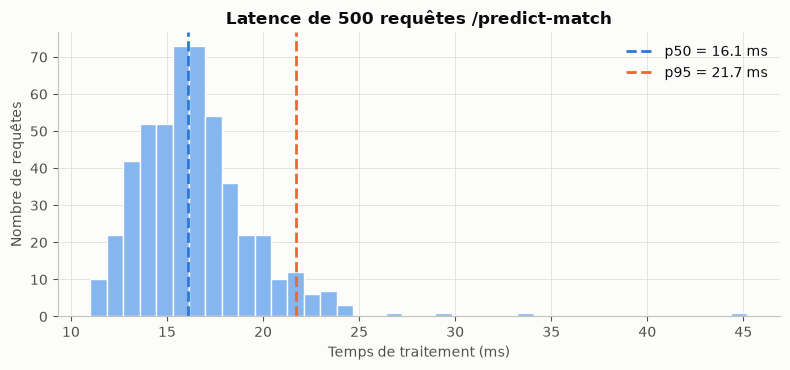

p50 16.1 ms · p95 21.7 ms · p99 24.3 ms · moyenne 16.5 ms


In [53]:
# --- outils pour lancer / arrêter le service réel (utilisés pour la latence ici et à l'étape 7) ---
import urllib.request, urllib.error
PORT = 8765
URL = f'http://127.0.0.1:{PORT}'

def demarrer_service():
    sortie = open(DEPLOY / 'logs' / 'uvicorn.out', 'w')
    proc = subprocess.Popen([sys.executable, '-m', 'uvicorn', 'app:app', '--host', '127.0.0.1', '--port', str(PORT)], cwd=DEPLOY, stdout=sortie, stderr=subprocess.STDOUT)
    for _ in range(60):                                         # on attend que /health réponde
        try:
            urllib.request.urlopen(URL + '/health', timeout=1); return proc
        except Exception: time.sleep(0.5)
    proc.terminate(); raise RuntimeError('service non démarré : voir football-api/logs/uvicorn.out')

def appeler(chemin, corps=None):                                # renvoie (code HTTP, JSON)
    req = urllib.request.Request(URL + chemin, data=None if corps is None else json.dumps(corps).encode(), headers={'Content-Type': 'application/json'})
    try:
        with urllib.request.urlopen(req, timeout=10) as rep: return rep.status, json.loads(rep.read())
    except urllib.error.HTTPError as e: return e.code, json.loads(e.read())

# --- latence sur 500 requêtes réelles (service lancé en local) ---
import httpx
proc = demarrer_service()
try:
    a, b = [int(i) for i in list(etat['equipes'])[:2]]
    corps = {'equipe_dom': a, 'equipe_ext': b, 'competition_type': COMPETITIONS[0]}
    lat = []
    with httpx.Client(base_url=URL) as c:
        for _ in range(20): c.post('/predict-match', json=corps)          # échauffement
        for _ in range(500):
            t0 = time.perf_counter(); c.post('/predict-match', json=corps); lat.append((time.perf_counter() - t0) * 1000)
finally:
    proc.terminate(); proc.wait()
p50, p95, p99 = np.percentile(lat, [50, 95, 99])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(lat, bins=40, color='#86b6ef', edgecolor='#fcfcfb')
for v, n, c in [(p50, 'p50', '#2a78d6'), (p95, 'p95', '#eb6834')]:
    ax.axvline(v, color=c, ls='--', lw=2, label=f'{n} = {v:.1f} ms')
ax.set(title='Latence de 500 requêtes /predict-match', xlabel='Temps de traitement (ms)', ylabel='Nombre de requêtes'); ax.legend()
plt.tight_layout(); plt.show()
print(f'p50 {p50:.1f} ms · p95 {p95:.1f} ms · p99 {p99:.1f} ms · moyenne {np.mean(lat):.1f} ms')

### 10.6 Étape 6 : conteneuriser et choisir l'hébergement
`Dockerfile` (image Python officielle, dépendances installées **avant** le code pour profiter du cache, utilisateur **non-root**, port exposé), `.dockerignore` et `requirements.txt` aux **versions figées** (le modèle sklearn doit être rechargé avec la même version).

| Option | Effort | Quand |
|---|---|---|
| Plateforme gérée (Render, Railway…) | faible | démo, petit projet, HTTPS inclus |
| Serveur / VPS | moyen | contrôle total, Waitress/Uvicorn + proxy |
| Cloud managé (conteneur) | variable | montée en charge, supervision intégrée |

In [54]:
import platform
from pathlib import Path
DEPLOY = Path.cwd()          # le notebook est dans le dossier football-api
from importlib.metadata import version
pins = ['fastapi', 'uvicorn', 'pydantic', 'scikit-learn', 'pandas', 'numpy', 'joblib']

def ecrire_si_absent(nom, texte):                              # ne jamais écraser un fichier déjà personnalisé (README, Dockerfile, requirements)
    f = DEPLOY / nom
    if f.exists():
        print(f'= {nom} existe déjà : conservé')
        return
    f.write_text(texte, encoding='utf-8')
    print(f'+ {nom} créé')

ecrire_si_absent('requirements.txt', '\n'.join(f'{p}=={version(p)}' for p in pins) + '\n')

py = f"{platform.python_version_tuple()[0]}.{platform.python_version_tuple()[1]}"
ecrire_si_absent('Dockerfile', "\n".join([
    "# Même version de Python que pour l'entraînement",
    f"FROM python:{py}-slim",
    "WORKDIR /app",
    "COPY requirements.txt .",
    "RUN pip install --no-cache-dir -r requirements.txt",
    "COPY app.py features.py ./",
    "COPY model/ model/",
    "COPY static/ static/",
    "RUN useradd --create-home appuser && mkdir -p logs && chown -R appuser /app",
    "USER appuser",
    "EXPOSE 8000",
    "HEALTHCHECK CMD python -c \"import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health')\" || exit 1",
    'CMD ["python", "-m", "uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]',
    "",
]))

ecrire_si_absent('.dockerignore', '.venv/\n.git/\n__pycache__/\nlogs/\n*.pyc\n*.ipynb\n.env\ntest_service.py\n')
ecrire_si_absent('README.md', "# football-api\n\npip install -r requirements.txt\npython -m uvicorn app:app --port 8000\npython -m pytest -q\ndocker compose up -d --build\n")

print((DEPLOY / 'requirements.txt').read_text())
DOSSIERS_IGNORES = {'.git', '.venv', 'logs', '__pycache__', '.ipynb_checkpoints'}
print('Fichiers du projet :', sorted(str(p.relative_to(DEPLOY)) for p in DEPLOY.rglob('*') if p.is_file() and not (DOSSIERS_IGNORES & set(p.relative_to(DEPLOY).parts))))

= requirements.txt existe déjà : conservé
= Dockerfile existe déjà : conservé
= .dockerignore existe déjà : conservé
= README.md existe déjà : conservé
fastapi==0.164.0
uvicorn==0.40.0
pydantic==2.13.4
scikit-learn==1.9.0
pandas==3.0.3
numpy==2.4.6
joblib==1.5.3

Fichiers du projet : ['.dockerignore', '.gitignore', '.pytest_cache\\.gitignore', '.pytest_cache\\CACHEDIR.TAG', '.pytest_cache\\README.md', '.pytest_cache\\v\\cache\\nodeids', '.vscode\\PythonImportHelper-v2-Completion.json', 'Dockerfile', 'Football_Resultat_Match_Pro_Complet.ipynb', 'README.md', 'app.py', 'docker-compose.yml', 'features.py', 'model\\etat_equipes.json', 'model\\metadata.json', 'model\\pipeline.joblib', 'requirements-dev.txt', 'requirements.txt', 'static\\index.html', 'test_service.py']


### 10.7 Étape 7 : démarrer et vérifier
Local : `python -m uvicorn app:app --port 8000` (documentation interactive automatique sur `/docs`). Docker : `docker build -t football-api:v1 .` puis `docker run -p 8000:8000 football-api:v1`.
Pour Internet, on place un **proxy inverse** (Caddy ou Nginx) devant le service : il gère **HTTPS** et transmet les requêtes à `127.0.0.1:8000` ; exemple Caddy :
```
api.exemple.fr {
    reverse_proxy 127.0.0.1:8000
}
```
Vérification réelle ci-dessous : service démarré, `/health` répond, une requête valide réussit, des requêtes invalides sont refusées avec le bon code.

In [55]:
proc = demarrer_service()
try:
    print('GET  /health        ->', appeler('/health'))
    a, b = [int(i) for i in list(etat['equipes'])[:2]]
    code_ok, rep = appeler('/predict-match', {'equipe_dom': a, 'equipe_ext': b, 'competition_type': COMPETITIONS[0]})
    print('POST /predict-match ->', code_ok, rep['prediction'], rep['probabilites'])
    print('POST invalide (compétition inconnue) ->', appeler('/predict-match', {'equipe_dom': a, 'equipe_ext': b, 'competition_type': 'xyz'})[0])
    print('POST invalide (équipe inconnue)      ->', appeler('/predict-match', {'equipe_dom': -5, 'equipe_ext': b, 'competition_type': COMPETITIONS[0]})[0])
    print('POST invalide (champ en trop)        ->', appeler('/predict-match', {'equipe_dom': a, 'equipe_ext': b, 'competition_type': COMPETITIONS[0], 'x': 1})[0])
    for _ in range(30): appeler('/predict-match', {'equipe_dom': a, 'equipe_ext': b, 'competition_type': COMPETITIONS[0]})   # un peu de trafic pour la supervision
finally:
    proc.terminate(); proc.wait()
print('Service arrêté. Pour le garder ouvert et tester la page web :  cd football-api  puis  python -m uvicorn app:app --port 8000')

GET  /health        -> (200, {'status': 'ok', 'model_version': 'football-v1', 'modele': 'Régression logistique', 'equipes': 1245})
POST /predict-match -> 200 Victoire domicile {'Victoire extérieur': 0.2996, 'Nul': 0.0593, 'Victoire domicile': 0.6411}
POST invalide (compétition inconnue) -> 422
POST invalide (équipe inconnue)      -> 404
POST invalide (champ en trop)        -> 422
Service arrêté. Pour le garder ouvert et tester la page web :  cd football-api  puis  python -m uvicorn app:app --port 8000


### 10.8 Étape 8 : surveiller et maintenir
Trois familles de contrôles du cours : **technique** (disponibilité, erreurs, latence p95), **données** (champs manquants, valeurs hors plage → refus 422 comptés), **modèle** (distribution des prédictions comparée à la référence d'entraînement, version, résultats cohérents). Le service écrit un **journal JSON** sans donnée personnelle (`logs/service.jsonl`).

Requêtes : 1917 · erreurs 4xx : 76 · erreurs 5xx : 0 · latence p95 : 20.5 ms


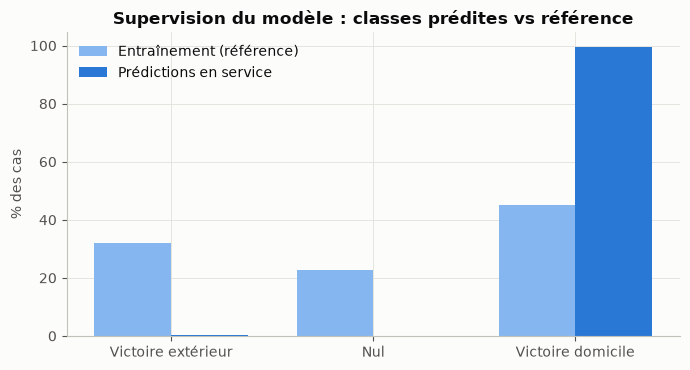

Si les prédictions s'écartent durablement de la référence (ou si le taux de 422 monte), il faut contrôler les données reçues puis ré-entraîner (nouvelle version football-v2).


In [56]:
lg = pd.read_json(DEPLOY / 'logs' / 'service.jsonl', lines=True)
rq = lg[lg['evt'] == 'requete']
rq_api = rq[rq['chemin'].isin(['/predict', '/predict-match'])]
print(f"Requêtes : {len(rq)} · erreurs 4xx : {(rq['statut'].between(400, 499)).sum()} · erreurs 5xx : {(rq['statut'] >= 500).sum()} · latence p95 : {rq_api['ms'].quantile(.95):.1f} ms")

pr = lg[lg['evt'] == 'prediction']
obs = pr['classe'].value_counts(normalize=True).reindex(LABELS).fillna(0)
ref = pd.Series(meta['prior_classes'], index=LABELS)
x = np.arange(3); w = 0.38
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x - w / 2, ref * 100, w, color='#86b6ef', label="Entraînement (référence)")
ax.bar(x + w / 2, obs * 100, w, color='#2a78d6', label='Prédictions en service')
ax.set_xticks(x); ax.set_xticklabels(LABELS); ax.set(title='Supervision du modèle : classes prédites vs référence', ylabel='% des cas'); ax.legend()
plt.tight_layout(); plt.show()
print('Si les prédictions s\'écartent durablement de la référence (ou si le taux de 422 monte), il faut contrôler les données reçues puis ré-entraîner (nouvelle version football-v2).')

**Liste de contrôle sécurité (Ch.7)** : ✔ entrées validées (schéma strict, taille limitée) · ✔ secrets hors du code (variables d'environnement, `.env` ignoré) · ✔ conteneur non-root · ✔ HTTPS via proxy inverse · ✔ pas de données personnelles dans les journaux · ◻ authentification et limitation de débit à ajouter si l'API devient publique.

**Erreurs fréquentes** : version de scikit-learn différente (→ `requirements.txt` figé) · résultats différents du notebook (→ pipeline complet, mêmes colonnes dans le même ordre) · service inaccessible de l'extérieur (→ `--host 0.0.0.0` dans Docker, port publié) · modèle rechargé à chaque requête (→ chargement au démarrage).

## 8 ter. Comparaison complète des modèles (cahier des charges)
On compare **8 algorithmes** : régression logistique, k-plus proches voisins, SVM, arbre de décision, forêt aléatoire, **bagging**, **boosting** (AdaBoost et gradient boosting). Chacun passe par le **même pipeline** (normalisation + encodage), est évalué par **validation croisée temporelle** (3 plis, on apprend sur le passé et on valide sur le futur), puis sur le **test temporel** avec précision, rappel, F1 et **AUC-ROC**. k-NN et SVM sont lents : ils sont entraînés sur un sous-échantillon (les 2 000 matchs les plus récents du passé).

In [ ]:
# ===== 8 ter.1 Comparaison de 8 modèles : validation croisée + test temporel + AUC-ROC =====
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score
from sklearn.preprocessing import label_binarize

N_LENT = 2000                                           # sous-échantillon pour les modèles lents (k-NN, SVM)
LENTS = ['k-NN (k=25)', 'SVM (noyau RBF)']
cv5 = TimeSeriesSplit(n_splits=3)                       # 3 plis temporels

modeles_cmp = {
    'Régression logistique': LogisticRegression(max_iter=2000),
    'k-NN (k=25)': KNeighborsClassifier(n_neighbors=25),
    'SVM (noyau RBF)': SVC(C=1, probability=True, random_state=42),
    'Arbre de décision': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Forêt aléatoire': RandomForestClassifier(n_estimators=50, min_samples_leaf=20, random_state=42, n_jobs=-1),
    'Bagging (arbres)': BaggingClassifier(DecisionTreeClassifier(max_depth=8), n_estimators=10, random_state=42, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(n_estimators=30, learning_rate=0.5, random_state=42),
    'Gradient boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100, random_state=42),
}
Yb = label_binarize(yb, classes=[0, 1, 2])              # cible en 3 colonnes (un-contre-tous) pour l'AUC et les courbes ROC
lignes, probas, pipes_cmp = [], {}, {}
for nom, est in modeles_cmp.items():
    t0 = time.perf_counter()
    pipe = Pipeline([('prep', preprocess()), ('clf', est)])
    Xs, ys = (Xa.tail(N_LENT), ya.tail(N_LENT)) if nom in LENTS else (Xa, ya)
    cvr = cross_validate(pipe, Xs, ys, cv=cv5, scoring=['accuracy', 'f1_macro'], n_jobs=1)      # validation croisée temporelle
    pipe.fit(Xs, ys)
    p = pipe.predict(Xb); pr = pipe.predict_proba(Xb)
    probas[nom], pipes_cmp[nom] = pr, pipe
    lignes.append([nom, cvr['test_accuracy'].mean(), cvr['test_accuracy'].std(), cvr['test_f1_macro'].mean(),
                   accuracy_score(yb, p), precision_score(yb, p, average='macro', zero_division=0), recall_score(yb, p, average='macro'),
                   f1_score(yb, p, average='macro'), roc_auc_score(yb, pr, multi_class='ovr', average='macro'), time.perf_counter() - t0])
    print(f'{nom} : {time.perf_counter() - t0:.0f} s')   # suivi de l'avancement
cmp_ = pd.DataFrame(lignes, columns=['Modèle', 'CV accuracy', 'CV écart-type', 'CV F1 macro', 'Test accuracy', 'Test précision (macro)',
                                     'Test rappel (macro)', 'Test F1 (macro)', 'Test AUC-ROC (macro)', 'Temps (s)']).set_index('Modèle')
print(f'Référence (toujours la classe majoritaire) : accuracy {ref_t:.3f} · AUC-ROC 0.500 (hasard)')
cmp_.sort_values('Test AUC-ROC (macro)', ascending=False).round(3)

In [ ]:
# ===== 8 ter.2 Graphiques comparatifs : accuracy, F1 et AUC-ROC par modèle =====
ordre = cmp_.sort_values('Test AUC-ROC (macro)').index
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (col, couleur, titre) in zip(axes, [('Test accuracy', '#2a78d6', 'Accuracy (test temporel)'), ('Test F1 (macro)', '#1baf7a', 'F1 macro (test temporel)'),
                                            ('Test AUC-ROC (macro)', '#eb6834', 'AUC-ROC macro (test temporel)')]):
    ax.barh(ordre, cmp_.loc[ordre, col], color=couleur, height=0.65)
    for i, v in enumerate(cmp_.loc[ordre, col]): ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8, color='#52514e')   # valeur au bout de la barre
    ax.set_title(titre); ax.set_xlim(0.3 if col != 'Test AUC-ROC (macro)' else 0.45, cmp_[col].max() + 0.06); ax.grid(axis='y', visible=False)
axes[0].axvline(ref_t, color='#52514e', ls='--', lw=1.2); axes[0].text(ref_t + 0.003, -0.6, 'référence', fontsize=8, color='#52514e')
axes[2].axvline(0.5, color='#52514e', ls='--', lw=1.2)
plt.tight_layout(); plt.show()

In [ ]:
# ===== 8 ter.3 Courbes ROC : meilleur modèle (par classe) et comparaison des 3 meilleurs (victoire à domicile) =====
meilleur_auc = cmp_['Test AUC-ROC (macro)'].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for k, lab in enumerate(LABELS):                                                  # un-contre-tous, une courbe par classe
    fpr, tpr, _ = roc_curve(Yb[:, k], probas[meilleur_auc][:, k])
    axes[0].plot(fpr, tpr, lw=2, color=COUL[lab], label=f"{lab} (AUC {roc_auc_score(Yb[:, k], probas[meilleur_auc][:, k]):.2f})")
axes[0].plot([0, 1], [0, 1], color='#898781', ls='--', lw=1)
axes[0].set(title=f'ROC par classe : {meilleur_auc}', xlabel='Taux de faux positifs', ylabel='Taux de vrais positifs'); axes[0].legend(loc='lower right')
top3 = cmp_['Test AUC-ROC (macro)'].nlargest(3).index
for nom, c in zip(top3, ['#6250d6', '#e87ba4', '#eda100']):
    fpr, tpr, _ = roc_curve(Yb[:, 2], probas[nom][:, 2])
    axes[1].plot(fpr, tpr, lw=2, color=c, label=f"{nom} (AUC {roc_auc_score(Yb[:, 2], probas[nom][:, 2]):.2f})")
axes[1].plot([0, 1], [0, 1], color='#898781', ls='--', lw=1)
axes[1].set(title='ROC « victoire à domicile » : 3 meilleurs modèles', xlabel='Taux de faux positifs', ylabel='Taux de vrais positifs'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()
print('Lecture : une courbe au-dessus de la diagonale = mieux que le hasard. Le « nul » est la classe la moins bien séparée (AUC la plus basse).')

In [ ]:
# ===== 8 ter.4 Optimisation étendue : réglage des hyperparamètres des autres modèles =====
reglages = {
    'k-NN (k=25)': (KNeighborsClassifier(), {'clf__n_neighbors': [15, 50]}, 'grille'),
    'SVM (noyau RBF)': (SVC(random_state=42), {'clf__C': [1, 5]}, 'grille'),
    'Forêt aléatoire': (RandomForestClassifier(random_state=42, n_jobs=-1, n_estimators=50),
                        {'clf__max_depth': [6, 10], 'clf__min_samples_leaf': [20, 50]}, 'aleatoire'),
    'AdaBoost': (AdaBoostClassifier(random_state=42, n_estimators=30), {'clf__learning_rate': [0.1, 0.5]}, 'grille'),
}
cv3 = TimeSeriesSplit(n_splits=3)
lignes = []
for nom, (est, grille, mode) in reglages.items():
    t0 = time.perf_counter()
    pipe = Pipeline([('prep', preprocess()), ('clf', est)])
    Xs, ys = (Xa.tail(N_LENT), ya.tail(N_LENT)) if nom in LENTS else (Xa, ya)
    rech = RandomizedSearchCV(pipe, grille, n_iter=2, cv=cv3, scoring='accuracy', random_state=42, n_jobs=1) if mode == 'aleatoire' \
        else GridSearchCV(pipe, grille, cv=cv3, scoring='accuracy', n_jobs=1)
    rech.fit(Xs, ys)
    p = rech.predict(Xb)
    lignes.append([nom, {k.replace('clf__', ''): v for k, v in rech.best_params_.items()}, rech.best_score_,
                   cmp_.loc[nom, 'Test accuracy'], accuracy_score(yb, p), f1_score(yb, p, average='macro'), time.perf_counter() - t0])
    print(f'{nom} : {time.perf_counter() - t0:.0f} s')
opt = pd.DataFrame(lignes, columns=['Modèle', 'Meilleurs hyperparamètres', 'CV accuracy (réglé)', 'Test accuracy (avant)', 'Test accuracy (après)',
                                    'Test F1 macro (après)', 'Temps (s)']).set_index('Modèle')
opt['Gain (points)'] = ((opt['Test accuracy (après)'] - opt['Test accuracy (avant)']) * 100).round(2)
opt.round(3)

In [ ]:
# ===== 8 ter.5 Synthèse : le réglage améliore-t-il vraiment ? =====
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(opt)); w = 0.38
ax.bar(x - w / 2, opt['Test accuracy (avant)'], w, color='#86b6ef', label='Avant réglage')
ax.bar(x + w / 2, opt['Test accuracy (après)'], w, color='#2a78d6', label='Après réglage')
ax.axhline(ref_t, color='#52514e', ls='--', lw=1.2); ax.text(len(opt) - 0.5, ref_t + 0.004, 'référence', fontsize=8, color='#52514e', ha='right')
ax.set_xticks(x); ax.set_xticklabels(opt.index); ax.set_ylim(0.4, max(opt['Test accuracy (après)'].max(), opt['Test accuracy (avant)'].max()) + 0.04)
ax.set(title='Effet du réglage des hyperparamètres (test temporel)', ylabel='Accuracy'); ax.legend(); plt.tight_layout(); plt.show()
meilleur_global = cmp_['Test AUC-ROC (macro)'].idxmax()
print(f"Meilleur AUC-ROC : {meilleur_global} ({cmp_.loc[meilleur_global, 'Test AUC-ROC (macro)']:.3f}) · meilleure accuracy : {cmp_['Test accuracy'].idxmax()} ({cmp_['Test accuracy'].max():.3f}) · référence {ref_t:.3f}")

**Conclusion de la comparaison** : tous les modèles bien réglés se placent dans un petit intervalle d'accuracy, au-dessus de la référence « classe majoritaire » mais loin de la perfection. Les modèles linéaires et le boosting sont aussi bons que les plus complexes (SVM, forêts) : le plafond vient de l'information disponible avant le match (le football reste très aléatoire), pas du choix de l'algorithme. Les méthodes ensemblistes (bagging, boosting) apportent surtout de la stabilité, et le réglage apporte peu aux modèles déjà bons (moins d'un point) mais davantage à k-NN, très sensible à son hyperparamètre k. Le modèle **déployé au §10** reste le pipeline retenu au §8 bis (meilleure validation croisée, simple et rapide) ; on pourrait le remplacer par un autre pipeline de ce tableau sans changer l'API.